# Cómo los datos y las reglas transformaron la NFL (1999–2025)


Miguel Ángel Castro Torreslanda

**Módulo:** Visualización de datos

---

## Resumen

Entre 1999 y 2025, la NFL (la liga profesional de fútbol americano de Estados Unidos) cambió mucho más de lo que parece a simple vista. Dos fuerzas explican buena parte de esa transformación:

1. **Los entrenadores empezaron a tomar decisiones basadas en datos.** Durante décadas, muchas decisiones del juego se tomaban por costumbre o intuición. Con la llegada de la analítica deportiva, algunas de esas costumbres resultaron ser errores, y los equipos cambiaron su forma de jugar.
2. **La liga cambió las reglas.** Por motivos de seguridad de los jugadores o para hacer el juego más atractivo, la NFL modificó reglas importantes, y cada cambio tuvo consecuencias (algunas buscadas y otras no).

Este trabajo cuenta esa historia a través de la visualización de **más de 1.2 millones de jugadas**. No se construye ningún modelo predictivo. El objetivo es que cada gráfica responda una pregunta concreta y que, juntas, formen un relato coherente sobre cómo y por qué cambió el juego.

## Estructura del trabajo

| Capítulo | Pregunta |
|---|---|
| **0. Cómo se juega y qué medimos** | ¿Qué es un *down*, cómo se anota y cómo sabemos si una jugada fue buena? |
| **1. Perderle el miedo al 4º down** | ¿Los datos decían que los equipos eran demasiado conservadores? ¿Cambió la liga? |
| **2. El alcance de los pateadores** | ¿Cuánto mejoraron los pateadores y a qué se debe? |
| **3. La liga reescribe las reglas** | ¿Qué consecuencias tuvieron los cambios en la patada de salida y en el punto extra? |
| **4. Cómo se anota** | ¿Son hoy más eficientes los ataques? ¿Por qué se anota tanto justo antes del descanso? |
| **5. Mitos y curiosidades** | ¿Qué creencias populares sobre el juego resisten el análisis de los datos? |
| **Conclusiones** | Hallazgos principales, limitaciones y referencias |

## Cómo ejecutar este notebook

El notebook está pensado para ejecutarse **de principio a fin, en orden**, con el kernel limpio. Los datos necesarios ya estan incluidos en el zip para facilitar la ejecucion, sin embargo, en la segunda celda, si no estan esos datos, esta la opcion de descargar los datos originales y construye otra vez el archivo reducido desde 0. Las versiones de las librerías utilizadas se imprimen en la primera celda de código y se incluyen en el fichero `requirements.txt` de la entrega.

Además de las librerías habituales de análisis de datos (pandas, numpy, matplotlib, seaborn, plotly, pyarrow y scipy), el notebook usa la librería **pywaffle** para los gráficos de waffle del Capítulo 3. Si no está instalada, se puede instalar con `pip install pywaffle`. Todas las dependencias, con sus versiones exactas, están en el fichero `requirements.txt`.

## Los datos

### Origen

Los datos provienen de **nflverse**, un proyecto de código abierto que recopila, limpia y publica gratuitamente los datos de la NFL. En concreto, se usan los ficheros de *play-by-play* (jugada por jugada) generados por el paquete **nflfastR**, que se descargan desde el repositorio público:

`https://github.com/nflverse/nflverse-data/releases/tag/pbp`

Hay un fichero por temporada (`play_by_play_AAAA.parquet`). Los datos de origen son los registros oficiales de cada partido que publica la propia NFL, y nflfastR les añade variables calculadas, como la probabilidad de victoria o los puntos esperados (que se explican más adelante).

### Qué es un dato de *play-by-play*

Cada fila del conjunto de datos es **una jugada**. Para cada jugada se registra, entre otras cosas:

- **El contexto:** temporada, semana, partido, equipos, marcador, tiempo restante, *down*, yardas por avanzar y posición en el campo.
- **Qué se hizo:** pase, carrera, patada, despeje, etc.
- **Qué pasó:** yardas ganadas, si hubo anotación, castigo, pérdida de balón, etc.
- **Métricas calculadas:** puntos esperados, probabilidad de victoria, etc.

### Alcance temporal y geográfico

| Dimensión | Alcance |
|---|---|
| **Temporal** | Temporadas **1999 a 2025** (27 temporadas completas). La temporada 2026, en curso al momento de hacer este trabajo, se excluye para no mezclar temporadas completas con una incompleta. |
| **Tipo de partido** | Temporada regular y playoffs. Salvo que se indique lo contrario, los análisis usan **solo temporada regular**, para comparar temporadas en igualdad de condiciones. |
| **Geográfico** | Partidos de la NFL, que se juegan en los estadios de los 32 equipos de Estados Unidos, más un pequeño número de partidos en **sede neutral** (los Super Bowls y los partidos de la serie internacional, como los de Londres, México o Alemania). |
| **Volumen** | **1,279,628 jugadas** de **7,273 partidos** (6,964 de temporada regular y 309 de playoffs). 94 partidos se jugaron en sede neutral. |

### Preparación de los datos

Los ficheros originales tienen más de 370 columnas por jugada y ocupan cerca de 500 MB. Para que el trabajo sea reproducible y la entrega sea ligera, se construyó un **fichero reducido** (incluido ya en el zip) que contiene solo:

- las temporadas 1999–2025,
- las columnas que realmente se usan en el análisis.

La columna de descripción textual de cada jugada (`desc`) solo se conserva en las patadas de salida, porque es la única forma de identificar las patadas cortas intencionales (*onside kicks*). En el resto de jugadas no se usa y ocuparía mucho espacio.

El fichero reducido (`data/nfl_pbp_1999_2025.parquet`, unos 43 MB) se incluye en la entrega, sin embargo, en la segunda celda, si no se encuentra dicho archivo se vuelve a descargar de internet y se genera nuevamente el archivo reducido. 

In [1]:
# Librerías y configuración general
import os
import platform
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as Patch
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pyarrow
import scipy
import pywaffle
from pywaffle import Waffle




# Rutas y temporadas del análisis
DATA_DIR = "data"
DATA_FILE = os.path.join(DATA_DIR, "nfl_pbp_1999_2025.parquet")
PRIMERA_TEMPORADA = 1999
ULTIMA_TEMPORADA = 2025

# Versiones utilizadas (para el requirements.txt)
print("Python    ", platform.python_version())
print("pandas    ", pd.__version__)
print("numpy     ", np.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn   ", sns.__version__)
print("plotly    ", plotly.__version__)
print("pyarrow   ", pyarrow.__version__)
print("scipy     ", scipy.__version__)
print("pywaffle  ", pywaffle.__version__)

Python     3.13.9
pandas     2.3.3
numpy      2.4.6
matplotlib 3.10.6
seaborn    0.13.2
plotly     6.3.0
pyarrow    21.0.0
scipy      1.16.3
pywaffle   1.2.0


### Construcción del fichero reducido

La siguiente celda solo hace trabajo la primera vez que se ejecuta el notebook:

1. Si el fichero reducido `data/nfl_pbp_1999_2025.parquet` **ya existe**, no hace nada.
2. Si **no existe**, descarga desde nflverse los ficheros de cada temporada (si no están ya en la carpeta `RAW_DIR`), se queda con las columnas necesarias y guarda el fichero reducido.

Después, el notebook trabaja siempre con el fichero reducido.

Al cargar los datos se aplica un único ajuste: **unificar las franquicias que cambiaron de ciudad** durante el periodo. Los Raiders pasaron de Oakland (`OAK`) a Las Vegas (`LV`), los Chargers de San Diego (`SD`) a Los Ángeles (`LAC`) y los Rams de St. Louis (`STL`) a Los Ángeles (`LA`). Como se trata del mismo equipo, se usa siempre la abreviatura actual, para que su historia no aparezca partida en dos.

In [2]:

RAW_DIR = os.path.join(DATA_DIR, "raw")

COLUMNAS = [
    # Identificación y contexto del partido
    "season", "season_type", "week", "game_id", "play_id", "game_date",
    "home_team", "away_team", "home_score", "away_score", "location", "roof", "temp",
    # Situación de la jugada
    "posteam", "defteam", "play_type", "desc", "down", "ydstogo", "yardline_100", "qtr",
    "game_seconds_remaining", "half_seconds_remaining", "score_differential",
    "total_home_score", "total_away_score",
    # Métricas calculadas por nflfastR
    "ep", "epa", "wp", "wpa",
    # Pases, carreras y QB
    "pass", "yards_gained", "qb_dropback", "sack", "qb_hit", "interception", "fumble_lost",
    "passer_player_id", "passer_player_name",
    # Anotaciones
    "touchdown", "td_team", "pass_touchdown", "rush_touchdown", "safety", "defensive_two_point_conv",
    "field_goal_result", "kick_distance", "kicker_player_name",
    "extra_point_result", "extra_point_attempt", "two_point_attempt", "two_point_conv_result",
    # Patadas de salida
    "touchback", "kickoff_out_of_bounds", "kickoff_fair_catch", "kickoff_downed",
    "own_kickoff_recovery", "return_touchdown",
    # Drives, 4º down, castigos y tiempos fuera
    "fixed_drive", "fixed_drive_result", "fourth_down_converted", "first_down",
    "penalty", "penalty_type", "penalty_team", "timeout", "timeout_team",
]

if os.path.exists(DATA_FILE):
    print("El fichero reducido ya existe:", DATA_FILE)
else:
    os.makedirs(RAW_DIR, exist_ok=True)
    partes = []
    for temporada in range(PRIMERA_TEMPORADA, ULTIMA_TEMPORADA + 1):
        ruta = os.path.join(RAW_DIR, f"play_by_play_{temporada}.parquet")
        if not os.path.exists(ruta):
            url = f"https://github.com/nflverse/nflverse-data/releases/download/pbp/play_by_play_{temporada}.parquet"
            print("Descargando", temporada, "...")
            urllib.request.urlretrieve(url, ruta)
        df = pd.read_parquet(ruta, columns=COLUMNAS)
        df = df[df["season_type"].isin(["REG", "POST"])]
        df.loc[df["play_type"] != "kickoff", "desc"] = None   # solo se necesita en patadas de salida
        partes.append(df)
    pbp_reducido = pd.concat(partes, ignore_index=True)
    pbp_reducido.to_parquet(DATA_FILE, compression="zstd", index=False)
    print("Fichero reducido guardado:", DATA_FILE)

print(f"Tamaño del fichero reducido: {os.path.getsize(DATA_FILE) / 1e6:.1f} MB")

El fichero reducido ya existe: data\nfl_pbp_1999_2025.parquet
Tamaño del fichero reducido: 43.3 MB


In [3]:
# Carga de los datos
pbp = pd.read_parquet(DATA_FILE)
pbp = pbp.sort_values(["game_id", "play_id"]).reset_index(drop=True)

# Unificar franquicias que cambiaron de ciudad
reubicados = {"OAK": "LV", "SD": "LAC", "STL": "LA"}
for col in ["posteam", "defteam", "home_team", "away_team", "penalty_team", "timeout_team", "td_team"]:
    pbp[col] = pbp[col].replace(reubicados)

# Temporada regular (la base de casi todos los análisis)
reg = pbp[pbp["season_type"] == "REG"]

partidos = pbp.drop_duplicates("game_id")
print("Temporadas:", pbp["season"].min(), "-", pbp["season"].max())
print(f"Jugadas: {len(pbp):,}")
print(f"Partidos: {pbp['game_id'].nunique():,}  "
      f"(temporada regular: {reg['game_id'].nunique():,}, playoffs: {pbp.loc[pbp['season_type'] == 'POST', 'game_id'].nunique():,})")
print("Partidos en sede neutral:", (partidos["location"] == "Neutral").sum())

Temporadas: 1999 - 2025
Jugadas: 1,279,628
Partidos: 7,273  (temporada regular: 6,964, playoffs: 309)
Partidos en sede neutral: 94


---

# Capítulo 0. Cómo se juega y qué medimos

Para entender las gráficas de este trabajo no hace falta ser experto en fútbol americano, pero sí conocer unas pocas reglas básicas. Esta sección las resume:

## * Guía rápida del fútbol americano

### El campo y el objetivo

El campo mide **100 yardas** (unos 91 metros) entre las dos líneas de gol, más una **zona de anotación** (*end zone*) de 10 yardas en cada extremo. Cada equipo tiene 11 jugadores en el campo. El equipo que tiene el balón (**la ofensiva** o el ataque) intenta avanzar hasta la zona de anotación rival; el otro equipo (**la defensa**) intenta impedirlo.

El partido dura **cuatro cuartos de 15 minutos**, divididos en dos mitades. Si al final hay empate, se juega un tiempo extra. Cuando quedan dos minutos de cada mitad, el reloj se detiene automáticamente (el *aviso de los dos minutos*), y cada equipo tiene tres tiempos fuera por mitad.

### Los *downs*: la regla central del juego

El ataque no avanza de forma continua, sino en **jugadas cortas** separadas por pausas. La regla fundamental es:

> **El ataque tiene cuatro intentos (*downs*) para avanzar al menos 10 yardas.**

- Si lo consigue, obtiene un nuevo **primer down**: otros cuatro intentos para avanzar otras 10 yardas.
- Si después de cuatro intentos no lo ha conseguido, **pierde el balón** en el punto donde terminó la jugada y el rival ataca desde ahí.

La situación de cada jugada se describe con dos números: el down y las yardas que faltan. Por ejemplo, **"3rd & 7"** (tercero y siete) significa que es el tercer intento y faltan 7 yardas para el primer down.

### El cuarto down: la decisión más importante

Como perder el balón en el propio campo es muy peligroso, cuando llega el **cuarto down** el ataque tiene tres opciones:

1. **Despejar (*punt*):** patear el balón lejos para que el rival empiece su ataque lo más atrás posible. Se renuncia a la posesión a cambio de terreno.
2. **Intentar un gol de campo (*field goal*):** si se está cerca de la portería rival, patear el balón entre los postes para ganar 3 puntos.
3. **Jugársela (*go for it*):** intentar una jugada normal para conseguir las yardas que faltan. Si sale bien, se conserva el balón; si sale mal, el rival recibe el balón en ese punto.

Durante décadas, la opción casi automática era despejar o patear. Si esa costumbre era correcta es precisamente la pregunta del Capítulo 1.

### Cómo se anota

| Forma de anotar | Puntos | Descripción |
|---|---|---|
| **Touchdown (TD)** | 6 | Llevar el balón a la zona de anotación rival, corriendo o recibiendo un pase. |
| **Punto extra** | 1 | Tras un touchdown, patear el balón entre los postes desde corta distancia. |
| **Conversión de dos puntos** | 2 | Tras un touchdown, en lugar del punto extra, intentar una jugada normal desde la yarda 2. |
| **Gol de campo** | 3 | Patear el balón entre los postes en una jugada normal. |
| **Safety** | 2 | Para la defensa, cuando derriba al portador del balón dentro de la zona de anotación del propio ataque. |

Tras cada anotación, y al inicio de cada mitad, el juego se reinicia con una **patada de salida** (*kickoff*): un equipo patea el balón hacia el otro, que intenta devolverlo lo más lejos posible.

### Tipos de jugada

En cada down, el ataque puede intentar básicamente dos cosas:

- **Pase:** el *quarterback* (QB), el jugador que dirige el ataque, lanza el balón a un compañero. Puede salir muy bien (gran avance) o muy mal (pase incompleto, intercepción del rival, o *sack*, cuando la defensa derriba al QB antes de que lance).
- **Carrera:** el balón se entrega a un jugador que intenta avanzar corriendo. Suele ganar menos yardas, pero es más segura.

### Pequeño glosario

| Término | Significado |
|---|---|
| **Snap** | El inicio de cada jugada, cuando el balón pasa del centro al QB. |
| **Línea de golpeo** (*line of scrimmage*) | Línea imaginaria donde está el balón antes de cada jugada. |
| **Drive** | Una posesión completa de un equipo, desde que recibe el balón hasta que lo pierde o anota. |
| **Zona roja** | Las últimas 20 yardas antes de la zona de anotación rival. |
| **Pérdida de balón** (*turnover*) | Una intercepción o un balón suelto (*fumble*) recuperado por el rival. |
| **Touchback** | Cuando una patada termina dentro o más allá de la zona de anotación y nadie la devuelve, el balón se coloca en un punto fijo del campo. |

## ¿Cómo sabemos si una jugada fue buena? Los puntos esperados (EPA)

### El problema de las yardas

La forma más intuitiva de medir una jugada son las **yardas ganadas**, pero las yardas engañan, porque el mismo avance vale cosas muy distintas según la situación:

- En **"3rd & 10"**, ganar 9 yardas es un **fracaso**: no se consigue el primer down y casi seguro habrá que despejar.
- En **"3rd & 1"**, ganar 2 yardas es un **éxito**: se consigue el primer down y el ataque continúa.
- Una **intercepción** son 0 yardas, pero es de las peores cosas que pueden pasar, porque el rival recibe el balón.
- Un **touchdown desde la yarda 1** es una sola yarda que vale 6 puntos.

Por eso, en lugar de yardas, este trabajo usa la métrica estándar de la analítica moderna del fútbol americano: los **puntos esperados**.

### Puntos esperados (EP)

Los **puntos esperados** (*Expected Points*, EP) de una situación responden a la pregunta: **"históricamente, desde esta situación, ¿cuántos puntos acaba anotando en promedio el equipo que tiene el balón?"**. Si la siguiente anotación del partido es del rival, cuenta como puntos negativos.

El valor depende del down, las yardas que faltan, la posición en el campo y el tiempo restante. Lo calcula nflfastR con un modelo estadístico entrenado con cientos de miles de jugadas históricas (Baldwin y Carl; ver referencias). Algunos valores típicos para un **1st & 10** en temporadas recientes:

| Posición del balón | Puntos esperados |
|---|---|
| En tu propia yarda 5 | ≈ 0.0 |
| En tu propia yarda 25 | ≈ +1.1 |
| En medio campo | ≈ +2.6 |
| En la yarda 25 del rival | ≈ +4.3 |
| En la yarda 10 del rival | ≈ +5.0 |

### Puntos esperados añadidos (EPA)

El **EPA** (*Expected Points Added*) de una jugada es simplemente **cuánto cambiaron los puntos esperados** con ella:

> **EPA = puntos esperados después de la jugada − puntos esperados antes de la jugada**

Si una jugada lleva al equipo de una situación que valía +1.1 puntos a otra que vale +2.6, su EPA es +1.5. Un EPA positivo significa que la jugada **mejoró** las perspectivas del equipo; uno negativo, que las **empeoró**.

A lo largo del trabajo también se usa la **tasa de éxito**: el porcentaje de jugadas con EPA positivo. Es una forma muy intuitiva de leer el EPA: "de cada 10 jugadas, cuántas mejoraron la situación del equipo".

### Limitaciones del EPA

El EPA es la mejor medida disponible en datos públicos, pero no es perfecta: depende de un modelo estadístico (que puede equivocarse en situaciones poco frecuentes), y una sola jugada puede tener un EPA muy alto o muy bajo por azar. Por eso, en este trabajo se analiza siempre en **promedios sobre muchas jugadas**, nunca jugada a jugada.

La siguiente gráfica muestra cómo crecen los puntos esperados a medida que el ataque avanza por el campo.

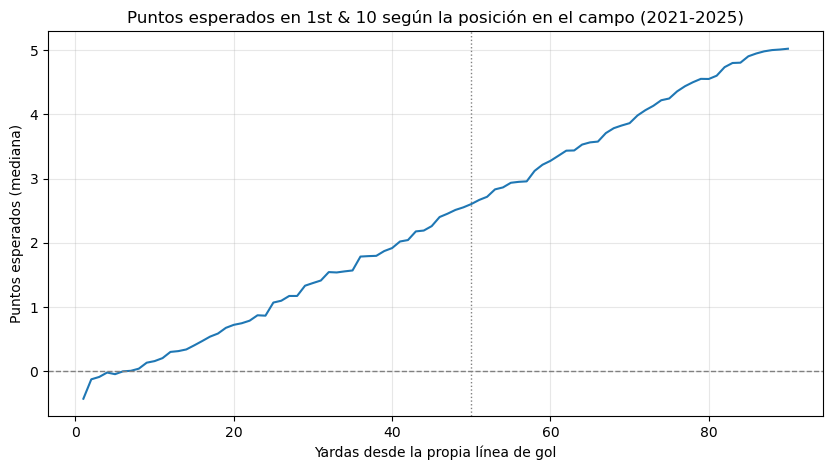

A 95 yardas de la zona de anotación rival: -0.04 puntos esperados
A 75 yardas de la zona de anotación rival: +1.07 puntos esperados
A 50 yardas de la zona de anotación rival: +2.60 puntos esperados
A 25 yardas de la zona de anotación rival: +4.25 puntos esperados
A 10 yardas de la zona de anotación rival: +5.02 puntos esperados


In [4]:
ep = reg[(reg["down"] == 1) & (reg["ydstogo"] == 10) & (reg["season"] >= 2021) & reg["ep"].notna()]
ep_por_yarda = ep.groupby("yardline_100")["ep"].median()
yardas_desde_propia_meta = 100 - ep_por_yarda.index

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yardas_desde_propia_meta, ep_por_yarda.values)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.axvline(50, color="gray", linestyle=":", linewidth=1)
ax.set_title("Puntos esperados en 1st & 10 según la posición en el campo (2021-2025)")
ax.set_xlabel("Yardas desde la propia línea de gol")
ax.set_ylabel("Puntos esperados (mediana)")
ax.grid(True, alpha=0.3)
plt.show()

for y in [95, 75, 50, 25, 10]:
    print(f"A {y} yardas de la zona de anotación rival: {ep_por_yarda.loc[y]:+.2f} puntos esperados")

La gráfica confirma la intuición: **cuanto más cerca de la zona de anotación rival, más puntos esperados**.

- **Cerca de la propia meta, los puntos esperados son prácticamente cero o negativos.** Desde ahí es difícil avanzar, y si el ataque fracasa y despeja, el rival recibirá el balón en buena posición. Es decir, lo más probable es que el *siguiente* que anote sea el rival.

## Anatomía de una jugada.

Antes de entrar en los cambios concretos, conviene tener una imagen general de **qué se juega en cada situación** y **con cuánto éxito**. Para ello se usan dos gráficos de tipo *sunburst* (gráfico de anillos jerárquico), uno para las cinco primeras temporadas del periodo (1999–2003) y otro para las cinco últimas (2021–2025).

**Cómo leer el gráfico:**

- **Anillo interior:** el down (1º, 2º, 3º o 4º). Su tamaño indica qué parte de todas las jugadas se juega en ese down.
- **Anillo intermedio:** el tipo de jugada elegido en ese down (pase, carrera, despeje o gol de campo). El porcentaje es **respecto a ese down**: por ejemplo, qué parte de los 4º downs fueron despejes.
- **Anillo exterior:** si la jugada fue un **éxito** (EPA positivo) o un **fracaso**. El porcentaje es **respecto al tipo de jugada**.

Se incluyen solo las jugadas "normales" de temporada regular como pases, carreras, despejes y goles de campo. Se excluyen las patadas de salida, los puntos extra y las jugadas anuladas por castigo. El gráfico es interactivo y al hacer clic en un segmento se amplía.

In [5]:

jugadas = reg[reg["play_type"].isin(["pass", "run", "punt", "field_goal"])
              & reg["down"].isin([1, 2, 3, 4])
              & reg["epa"].notna()].copy()

jugadas["Down"] = jugadas["down"].astype(int).map({1: "1er down", 2: "2º down", 3: "3er down", 4: "4º down"})
jugadas["Tipo de jugada"] = jugadas["play_type"].map({"pass": "Pase", "run": "Carrera",
                                                      "punt": "Despeje", "field_goal": "Gol de campo"})
jugadas["Resultado"] = np.where(jugadas["epa"] > 0, "Éxito", "Fracaso")

periodos = {"1999-2003": (1999, 2003), "2021-2025": (2021, 2025)}

colores = {
    # Anillo interior: downs (tonos de azul)
    "1er down": "#9ecae1", "2º down": "#6baed6", "3er down": "#3182bd", "4º down": "#08519c",
    # Anillo intermedio: tipo de jugada
    "Pase": "#ff7f0e", "Carrera": "#9467bd", "Despeje": "#7f7f7f", "Gol de campo": "#bcbd22",
    # Anillo exterior: resultado
    "Éxito": "#2ca02c", "Fracaso": "#d62728",
}

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "domain"}, {"type": "domain"}]],
                    subplot_titles=[f"Temporadas {nombre}" for nombre in periodos])

for i, (nombre, (inicio, fin)) in enumerate(periodos.items(), start=1):
    datos = jugadas[jugadas["season"].between(inicio, fin)]
    conteo = datos.groupby(["Down", "Tipo de jugada", "Resultado"]).size().reset_index(name="Jugadas")
    sb = px.sunburst(conteo, path=["Down", "Tipo de jugada", "Resultado"], values="Jugadas")
    traza = sb.data[0]
    traza.marker.colors = [colores[etiqueta] for etiqueta in traza.labels]
    fig.add_trace(traza, row=1, col=i)

fig.update_traces(
    textinfo="label+percent parent",
    hovertemplate="<b>%{label}</b><br>%{percentParent:.1%} de %{parent}<br>%{value:,} jugadas<extra></extra>",
)
fig.update_layout(title="Anatomía de una jugada: inicio del periodo frente a hoy", width=1200, height=650)
fig.show()

In [6]:
filas = []
for nombre, (inicio, fin) in periodos.items():
    datos = jugadas[jugadas["season"].between(inicio, fin)]
    reparto_down = datos["Down"].value_counts(normalize=True) * 100
    por_tipo = datos.groupby(["Down", "Tipo de jugada"]).agg(jugadas=("epa", "size"),
                                                            exito=("epa", lambda x: (x > 0).mean() * 100))
    por_tipo["% del down"] = por_tipo["jugadas"] / por_tipo.groupby(level=0)["jugadas"].transform("sum") * 100
    por_tipo["periodo"] = nombre
    filas.append(por_tipo)
    print(f"{nombre} · % de jugadas en cada down:", reparto_down.round(1).sort_index().to_dict())

tabla = pd.concat(filas).reset_index()
tabla = tabla.pivot_table(index=["Down", "Tipo de jugada"], columns="periodo", values=["% del down", "exito"])
print(tabla.round(1))

1999-2003 · % de jugadas en cada down: {'1er down': 39.5, '2º down': 30.0, '3er down': 19.5, '4º down': 11.1}
2021-2025 · % de jugadas en cada down: {'1er down': 40.0, '2º down': 30.5, '3er down': 19.0, '4º down': 10.6}
                        % del down               exito          
periodo                  1999-2003 2021-2025 1999-2003 2021-2025
Down     Tipo de jugada                                         
1er down Carrera              51.9      51.8      35.1      37.5
         Gol de campo          0.2       0.2      67.4      78.6
         Pase                 47.9      48.0      46.3      47.8
2º down  Carrera              45.3      41.0      38.0      43.6
         Gol de campo          0.2       0.3      68.3      81.3
         Pase                 54.5      58.7      43.2      46.2
3er down Carrera              23.9      24.6      51.0      56.5
         Despeje               0.0       NaN       0.0       NaN
         Gol de campo          0.3       0.5      75.0      77.1


### Qué nos dice la anatomía de una jugada

**1. El reparto entre downs apenas cambia.** En ambos periodos, alrededor del 40% de las jugadas se juegan en 1er down, el 30% en 2º, el 19% en 3º y el 11% en 4º. La estructura básica del juego es la misma.

**2. Los primeros downs se juegan casi igual que hace 25 años.** En 1er down, el reparto entre pase y carrera es prácticamente idéntico (en torno a 48% de pases y 52% de carreras). En 2º down, en cambio, el pase gana algo de terreno: del 54.5% al 58.7% de las jugadas.

**3. El gran cambio está en el 4º down.** Es el anillo que más se transforma entre los dos gráficos:

| 4º down | 1999–2003 | 2021–2025 |
|---|---|---|
| Despeje | 65.0% | 54.3% |
| Gol de campo | 22.6% | 25.2% |
| Pase | 7.5% | 12.8% |
| Carrera | 4.9% | 7.7% |
| **Jugársela (pase + carrera)** | **12.4%** | **20.5%** |

Hoy, **uno de cada cinco cuartos downs se juega**, frente a uno de cada ocho hace unas decadas. Ese cambio, y si los datos lo justificaban desde antes, es el tema del Capítulo 1.

**4. Hoy casi todo sale un poco mejor.** La tasa de éxito aumenta en casi todos los segmentos. Destacan dos:

- **Los goles de campo en 4º down** pasan de un 78.8% a un 85.7% de éxito. Los pateadores son mucho mejores que antes, que es el tema del Capítulo 2.
- **Jugársela en 4º down también funciona mejor**, las carreras pasan de un 59.8% a un 68.8% de éxito y los pases de un 37.6% a un 44.0%.

**5. Una advertencia sobre cómo leer el éxito.** Las tasas de éxito dependen también de *en qué situaciones* se elige cada jugada. Por ejemplo, en 3er down las carreras tienen mucho más éxito que los pases (56.5% frente a 38.3% hoy), pero no porque correr sea "mejor": los equipos suelen correr en 3er down cuando faltan muy pocas yardas, y pasar cuando faltan muchas. Del mismo modo, los despejes "exitosos" bajan del 51.8% al 41.5%, y una explicación posible es que hoy los equipos solo despejan en las situaciones más difíciles, porque en las fáciles se la juegan. Este tipo de efecto de selección se tendrá en cuenta a lo largo del trabajo.

---

# Capítulo 1. Perderle el miedo al 4º down

## Una costumbre que nadie cuestionaba

Como se explicó en la guía, cuando llega el cuarto down el ataque tiene tres opciones: despejar, intentar un gol de campo o jugársela. Durante décadas, la respuesta casi automática fue **patear**, despejar si se estaba lejos y gol de campo si se estaba cerca. Jugársela se veía como una apuesta temeraria, reservada para situaciones desesperadas.

Esa costumbre tenía una lógica aparente, en teoría, si te la juegas y fallas, le regalas al rival el balón en buena posición, y esto era algo inaceptable. Pero esa lógica solo mira uno de los lados de la balanza. También hay un costo en **no** jugársela, ya que despejar es renunciar voluntariamente a la posesión, e incluso patear un gol de campo es conformarse con 3 puntos cuando se podría aspirar a 7.

## El estudio que lo cuestionó: David Romer

En 2006, el economista **David Romer** (Universidad de California, Berkeley) publicó en el *Journal of Political Economy* un artículo titulado *"Do Firms Maximize? Evidence from Professional Football"* ("¿Maximizan las empresas? Evidencia del fútbol profesional"). Su objetivo no era el fútbol en sí, sino una pregunta de economía: ¿las organizaciones toman siempre las decisiones que más les convienen? El cuarto down era un caso ideal para comprobarlo, porque la decisión es sencilla, se repite miles de veces y su resultado se puede medir.

Romer analizó todos los cuartos downs del primer cuarto de los partidos de 1998 a 2000. Primero calculó cuánto "valía" estar en cada punto del campo, una idea muy parecida a los puntos esperados que usamos en este trabajo. Después comparó, para cada situación, el valor esperado de patear con el valor esperado de jugársela.

Su conclusión fue contundente: **los equipos eran sistemáticamente demasiado conservadores**. Encontró unas 1,100 situaciones en las que lo óptimo era jugársela, y en el 90% de ellas los entrenadores patearon. En este estudio Romer sugirió que los entrenadores no solo quieren ganar, sino que el fracaso visible tambien era algo importante para ellos, y por esta razon, una apuesta fallida en cuarto down se recuerda (y se critica) mucho más que un despeje "prudente" que acaba igualmente en derrota.

El estudio tuvo bastante eco en los medios, pero en los años siguientes los equipos no cambiaron su comportamiento de forma apreciable.

## Las preguntas de este capítulo

1. **¿Cuánto y cuándo cambió la liga?** ¿Hubo una evolución gradual o un cambio brusco?
2. **¿Los datos ya lo decían entonces?** Con nuestros propios datos, ¿se puede comprobar que jugársela era mejor en la época de Romer?
3. **¿Dónde cambió?** ¿En qué situaciones del campo se perdió el miedo y en cuáles no?
4. **¿Qué consecuencias tuvo?** ¿Cómo cambió lo que pasa después de cada 4º down?

## Qué jugadas se analizan

Para que la comparación sea justa, se usan solo los cuartos downs de temporada regular en **situación de partido normal**, que definimos con dos condiciones:

- **El partido no está decidido:** la probabilidad de victoria del equipo con el balón está entre el 10% y el 90%. Un equipo que pierde por 30 puntos se la juega por desesperación, no por estrategia, y uno que gana por 30 no necesita arriesgar.
- **No quedan menos de dos minutos de cada mitad:** al final de cada mitad, la decisión depende sobre todo del reloj.

Se consideran las cuatro jugadas posibles en un 4º down: pase o carrera (*jugársela*), gol de campo y despeje.

In [7]:

cuarto = reg[(reg["down"] == 4)
             & reg["play_type"].isin(["pass", "run", "punt", "field_goal"])
             & reg["wp"].between(0.1, 0.9)
             & (reg["half_seconds_remaining"] > 120)].copy()

cuarto["decision"] = np.select(
    [cuarto["play_type"].isin(["pass", "run"]), cuarto["play_type"] == "field_goal"],
    ["Jugársela", "Gol de campo"], default="Despeje")
cuarto["se_la_juega"] = cuarto["decision"] == "Jugársela"


cuarto["distancia"] = pd.cut(cuarto["ydstogo"], bins=[0, 1, 3, 5, 99],
                             labels=["4th & 1", "4th & 2-3", "4th & 4-5", "4th & 6+"])


cuarto["zona"] = pd.cut(cuarto["yardline_100"], bins=[0, 29, 39, 60, 99],
                        labels=["Rival 1-29", "Rival 30-39", "Medio campo", "Propio 1-39"])

print(f"Cuartos downs analizados: {len(cuarto):,}")
print(cuarto["decision"].value_counts())

Cuartos downs analizados: 68,666
decision
Despeje         45978
Gol de campo    16461
Jugársela        6227
Name: count, dtype: int64


## 1. ¿Cuánto y cuándo cambió la liga?

La primera gráfica muestra, temporada a temporada, **qué porcentaje de los cuartos downs se jugaron** (en lugar de patear), separando por las yardas que faltaban. Es importante separar por distancia, porque no es lo mismo jugársela en un "4th & 1" (falta una yarda) que en un "4th & 8" porque claramente la probabilidad de conseguirlo es muy distinta.

La línea discontinua negra muestra el total de todas las distancias juntas.

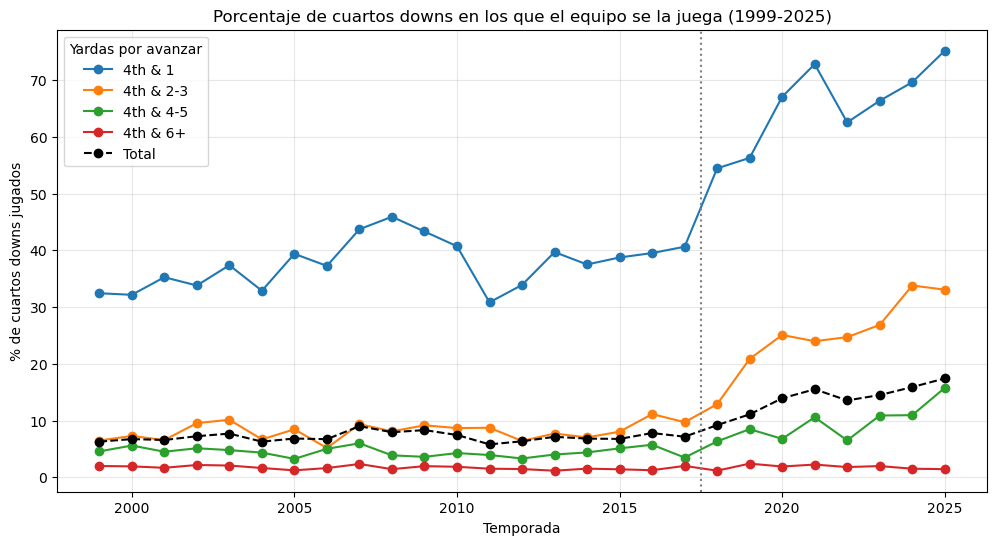

In [8]:
tasa = cuarto.groupby(["season", "distancia"], observed=True)["se_la_juega"].mean().unstack() * 100
total = cuarto.groupby("season")["se_la_juega"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
for col in tasa.columns:
    ax.plot(tasa.index, tasa[col], marker="o", label=col)
ax.plot(total.index, total.values, color="black", linestyle="--", marker="o", label="Total")
ax.axvline(2017.5, color="gray", linestyle=":")
ax.set_title("Porcentaje de cuartos downs en los que el equipo se la juega (1999-2025)")
ax.set_xlabel("Temporada")
ax.set_ylabel("% de cuartos downs jugados")
ax.legend(title="Yardas por avanzar")
ax.grid(True, alpha=0.3)
plt.show()

In [9]:
# Valores de apoyo para el texto
tabla_tasa = tasa.copy()
tabla_tasa["Total"] = total
print(tabla_tasa.round(1))
print(f"\nPromedio 1999-2017 (total): {total.loc[1999:2017].mean():.1f}%")

distancia  4th & 1  4th & 2-3  4th & 4-5  4th & 6+  Total
season                                                   
1999          32.4        6.5        4.6       2.0    6.3
2000          32.2        7.3        5.6       1.9    6.7
2001          35.3        6.6        4.5       1.7    6.6
2002          33.8        9.5        5.1       2.2    7.2
2003          37.4       10.1        4.8       2.1    7.7
2004          32.9        6.7        4.3       1.6    6.3
2005          39.4        8.5        3.3       1.2    6.8
2006          37.2        5.2        5.0       1.6    6.7
2007          43.7        9.4        6.0       2.3    9.0
2008          45.9        8.1        3.9       1.4    7.9
2009          43.3        9.2        3.6       2.0    8.3
2010          40.7        8.7        4.3       1.9    7.5
2011          30.8        8.7        3.9       1.5    5.8
2012          33.9        6.4        3.3       1.5    6.3
2013          39.7        7.7        4.0       1.2    7.1
2014          

### Qué muestra la gráfica

**No hubo una evolución gradual, sino un cambio brusco.** Entre 1999 y 2017, el porcentaje total de cuartos downs jugados se mantuvo prácticamente plano, en torno al **7%**, con oscilaciones normales de un año a otro. A partir de **2018** la curva se dispara: 9.2% ese año, 11.1% en 2019, 13.9% en 2020 y **17.4% en 2025**. En menos de una década, la frecuencia se multiplicó por dos y media.

El cambio se concentra en las distancias cortas, que es exactamente donde jugársela tiene más sentido:

| Situación | 1999 | 2025 |
|---|---|---|
| **4th & 1** | 32.4% | **75.2%** |
| **4th & 2-3** | 6.5% | **33.1%** |
| **4th & 4-5** | 4.6% | 15.8% |
| **4th & 6+** | 2.0% | 1.4% |

Hoy, en un "4th & 1", los equipos se la juegan **tres de cada cuatro veces**; a principios de siglo era menos de una de cada tres. En cambio, cuando faltan 6 yardas o más, la conducta es la misma que hace 25 años y casi nunca se la juegan. Esto sugiere que el cambio no es una "moda de arriesgar más", sino una **mejor evaluación del riesgo**, es decir se arriesga más donde las probabilidades son buenas, y no donde son malas.

### ¿Por qué tardó tanto?

El estudio de Romer se publicó en 2006 (y circulaba desde antes), pero la liga tardó más de una década en reaccionar. Los datos no permiten saber con certeza por qué el cambio llegó justo en 2018, pero hay varias hipótesis razonables:

- **La llegada de la analítica a los equipos.** En esos años, cada vez más equipos incorporaron departamentos de análisis de datos, y aparecieron herramientas públicas que calculan, jugada a jugada, cuál es la decisión óptima en cada cuarto down.
- **Un relevo generacional de entrenadores**, más abiertos a decisiones basadas en datos.

Estas hipótesis no se pueden comprobar con los datos de este trabajo, pero ayudan a entender que el cambio fue **cultural** más que técnico, ya que la información existía desde hacía años; lo que cambió fue la disposición a usarla.

La pregunta siguiente es si, efectivamente, **los datos ya daban la razón a Romer** en aquella época.

## 2. ¿Los datos ya lo decían en la época de Romer?

Para comprobarlo, se toman las temporadas **1999 a 2005**, es decir, el periodo de Romer y los años inmediatamente posteriores, cuando todavía casi nadie se la jugaba. Se miran las dos situaciones más claras, **"4th & 1"** y **"4th & 2"**, y se compara el **EPA promedio** de cada decisión según la zona del campo.

Las zonas del campo están ordenadas desde la propia portería hasta la del rival:

| Zona | Significado |
|---|---|
| **Propio 1-39** | En el propio campo, lejos de la zona de anotación rival. |
| **Medio campo** | Entre la propia yarda 40 y la yarda 40 del rival. |
| **Rival 30-39** | En la "tierra de nadie": demasiado lejos para un gol de campo cómodo y demasiado cerca para que valga la pena despejar. |
| **Rival 1-29** | Cerca de la zona de anotación rival, en rango de gol de campo. |

**Cómo leer la gráfica:** cada barra es el EPA promedio de una decisión en una zona. Una barra **por encima de cero** significa que esa decisión, en promedio, mejoró la situación del equipo, y **por debajo de cero**, que la empeoró. La línea negra sobre cada barra es el **intervalo de confianza del 95%**. Cuanto más larga, menos jugadas hay detrás y menos seguro es el valor. Si en una zona falta alguna barra, es porque esa decisión casi no se tomó allí.

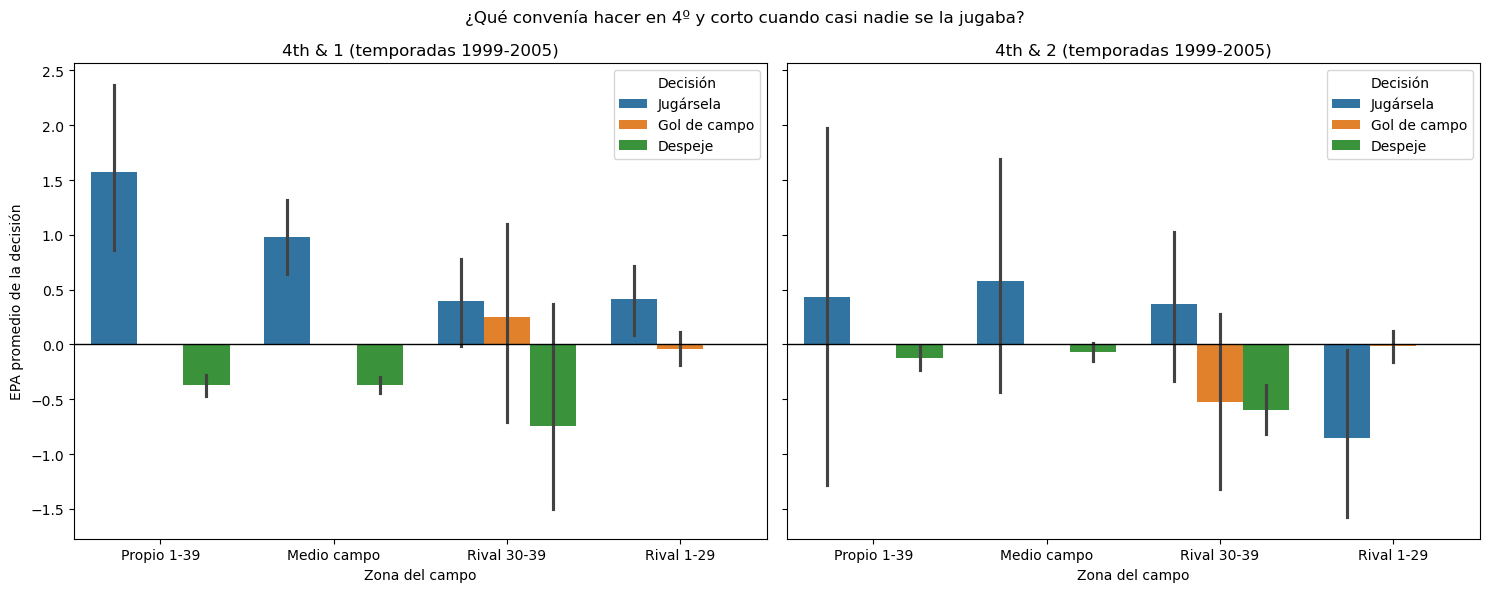

In [10]:
romer = cuarto[cuarto["season"].between(1999, 2005) & cuarto["ydstogo"].isin([1, 2])]
orden_zonas = ["Propio 1-39", "Medio campo", "Rival 30-39", "Rival 1-29"]
orden_decision = ["Jugársela", "Gol de campo", "Despeje"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, yardas in zip(axes, [1, 2]):
    sns.barplot(data=romer[romer["ydstogo"] == yardas], x="zona", y="epa", hue="decision",
                order=orden_zonas, hue_order=orden_decision, ax=ax)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"4th & {yardas} (temporadas 1999-2005)")
    ax.set_xlabel("Zona del campo")
    ax.set_ylabel("EPA promedio de la decisión")
    ax.legend(title="Decisión")
plt.suptitle("¿Qué convenía hacer en 4º y corto cuando casi nadie se la jugaba?")
plt.tight_layout()
plt.show()

In [11]:
# Valores de apoyo para el texto
apoyo = romer.groupby(["ydstogo", "zona", "decision"], observed=True).agg(
    jugadas=("epa", "size"), epa=("epa", "mean"), wpa=("wpa", "mean"))
print(apoyo.round(3))

se_la_jugaba = romer.groupby(["ydstogo", "zona"], observed=True)["se_la_juega"].mean().unstack(0) * 100
print("\n% de veces que se la jugaban (1999-2005):")
print(se_la_jugaba.round(1))

conv = romer[romer["se_la_juega"]].groupby(["ydstogo", "zona"], observed=True)["fourth_down_converted"].mean().unstack(0) * 100
print("\n% de conversión cuando se la jugaban:")
print(conv.round(1))

                                  jugadas    epa    wpa
ydstogo zona        decision                           
1.0     Rival 1-29  Gol de campo      275 -0.038 -0.024
                    Jugársela         308  0.417  0.013
        Rival 30-39 Despeje             9 -0.740 -0.039
                    Gol de campo       23  0.247 -0.015
                    Jugársela         167  0.399  0.016
        Medio campo Despeje           452 -0.372 -0.017
                    Jugársela         196  0.983  0.037
        Propio 1-39 Despeje           563 -0.373 -0.016
                    Jugársela          33  1.576  0.048
2.0     Rival 1-29  Gol de campo      371 -0.018 -0.019
                    Jugársela          48 -0.850 -0.039
        Rival 30-39 Despeje            29 -0.594 -0.041
                    Gol de campo       39 -0.524 -0.023
                    Jugársela          64  0.368  0.010
        Medio campo Despeje           379 -0.069 -0.014
                    Jugársela          26  0.580

### Como podemos ver parece que los datos ya daban la razón a Romer

**En "4th & 1", jugársela era mejor en todas las zonas del campo.** La diferencia es especialmente llamativa en las zonas donde los equipos casi nunca se arriesgaban:

| 4th & 1 (1999-2005) | EPA de jugársela | EPA de la alternativa | % de veces que se la jugaban |
|---|---|---|---|
| **Propio 1-39** | **+1.58** | −0.37 (despeje) | **5.5%** |
| **Medio campo** | **+0.98** | −0.37 (despeje) | 30.2% |
| **Rival 30-39** | +0.40 | +0.25 (gol de campo) | 83.9% |
| **Rival 1-29** | +0.42 | −0.04 (gol de campo) | 52.8% |

En medio campo, por ejemplo, jugársela aportaba en promedio casi **un punto esperado** (+0.98), mientras que despejar *restaba* (−0.37). La diferencia es de más de 1.3 puntos por decisión, y aun así los equipos despejaban en 7 de cada 10 ocasiones. En su propio campo, la diferencia era todavía mayor, y se la jugaban apenas un 5.5% de las veces.

¿Por qué funcionaba tan bien jugársela? Porque **en 4th & 1 los equipos conseguían el primer down entre el 64% y el 85% de las veces**, según la zona. Es decir, la apuesta "temeraria" salía bien en la gran mayoría de los casos.

**En "4th & 2" la conclusión se mantiene, con una excepción.** Jugársela también era mejor que despejar en el propio campo, en medio campo y en la "tierra de nadie" (Rival 30-39). Pero **cerca de la portería rival (Rival 1-29), el gol de campo era la mejor opción**: jugársela daba en promedio −0.85, frente a −0.02 del gol de campo. Esto es importante porque demuestra que el análisis no está "a favor" de arriesgar siempre, sino que dice que hay que arriesgar **donde compensa**, y que donde un gol de campo es casi seguro y la conversión es más difícil, conviene patear.

La misma conclusión se obtiene si, en lugar de los puntos esperados, se mira el **cambio en la probabilidad de victoria** (WPA, impreso en la celda anterior): jugársela en 4th & 1 aumentaba la probabilidad de ganar, mientras que despejar la reducía.

### Una advertencia

Estos números tienen un sesgo que hay que reconocer: en la época de Romer, los equipos **solo se la jugaban cuando creían tener buenas posibilidades** (por ejemplo, cuando la yarda que faltaba era "muy corta" o cuando tenían un buen corredor). Eso puede inflar un poco el éxito de jugársela. También algunas barras se basan en pocas jugadas, como jugársela en el propio campo en 4th & 2 (solo 10 casos), y por eso sus intervalos de confianza son largos.

Aun así, en las situaciones con muchas jugadas detrás, la diferencia es tan grande que el sesgo no basta para explicarla. Y en este sentido creo que **la evidencia de que los equipos eran demasiado conservadores existía, y estaba en los propios datos de la época.**

## 3. ¿Dónde se perdió el miedo? El mapa del atrevimiento

La gráfica anterior agrupa el campo en cuatro zonas. Para ver el cambio con más detalle, el siguiente mapa de calor divide el campo en tramos de 10 yardas y la distancia por avanzar en siete grupos. Cada casilla muestra **qué porcentaje de los cuartos downs se jugaron** en esa combinación de posición y distancia.

**Cómo leer el mapa:**

- **Eje horizontal:** la posición del balón, de izquierda (cerca de la propia portería) a derecha (cerca de la portería rival). "Propio" es la mitad del campo del equipo que ataca y "Rival" la del contrario.
- **Eje vertical:** las yardas que faltan para el primer down, de 1 (arriba) a 10 o más (abajo).
- **Color y número:** el porcentaje de veces que el equipo se la jugó. Cuanto más claro, más atrevimiento.

Se muestran tres mapas: el de **1999-2005**, el de **2021-2025** y la **diferencia** entre ambos (en puntos porcentuales; en rojo, donde más creció). Las casillas en blanco corresponden a combinaciones con menos de 25 jugadas, en las que el porcentaje no sería fiable.

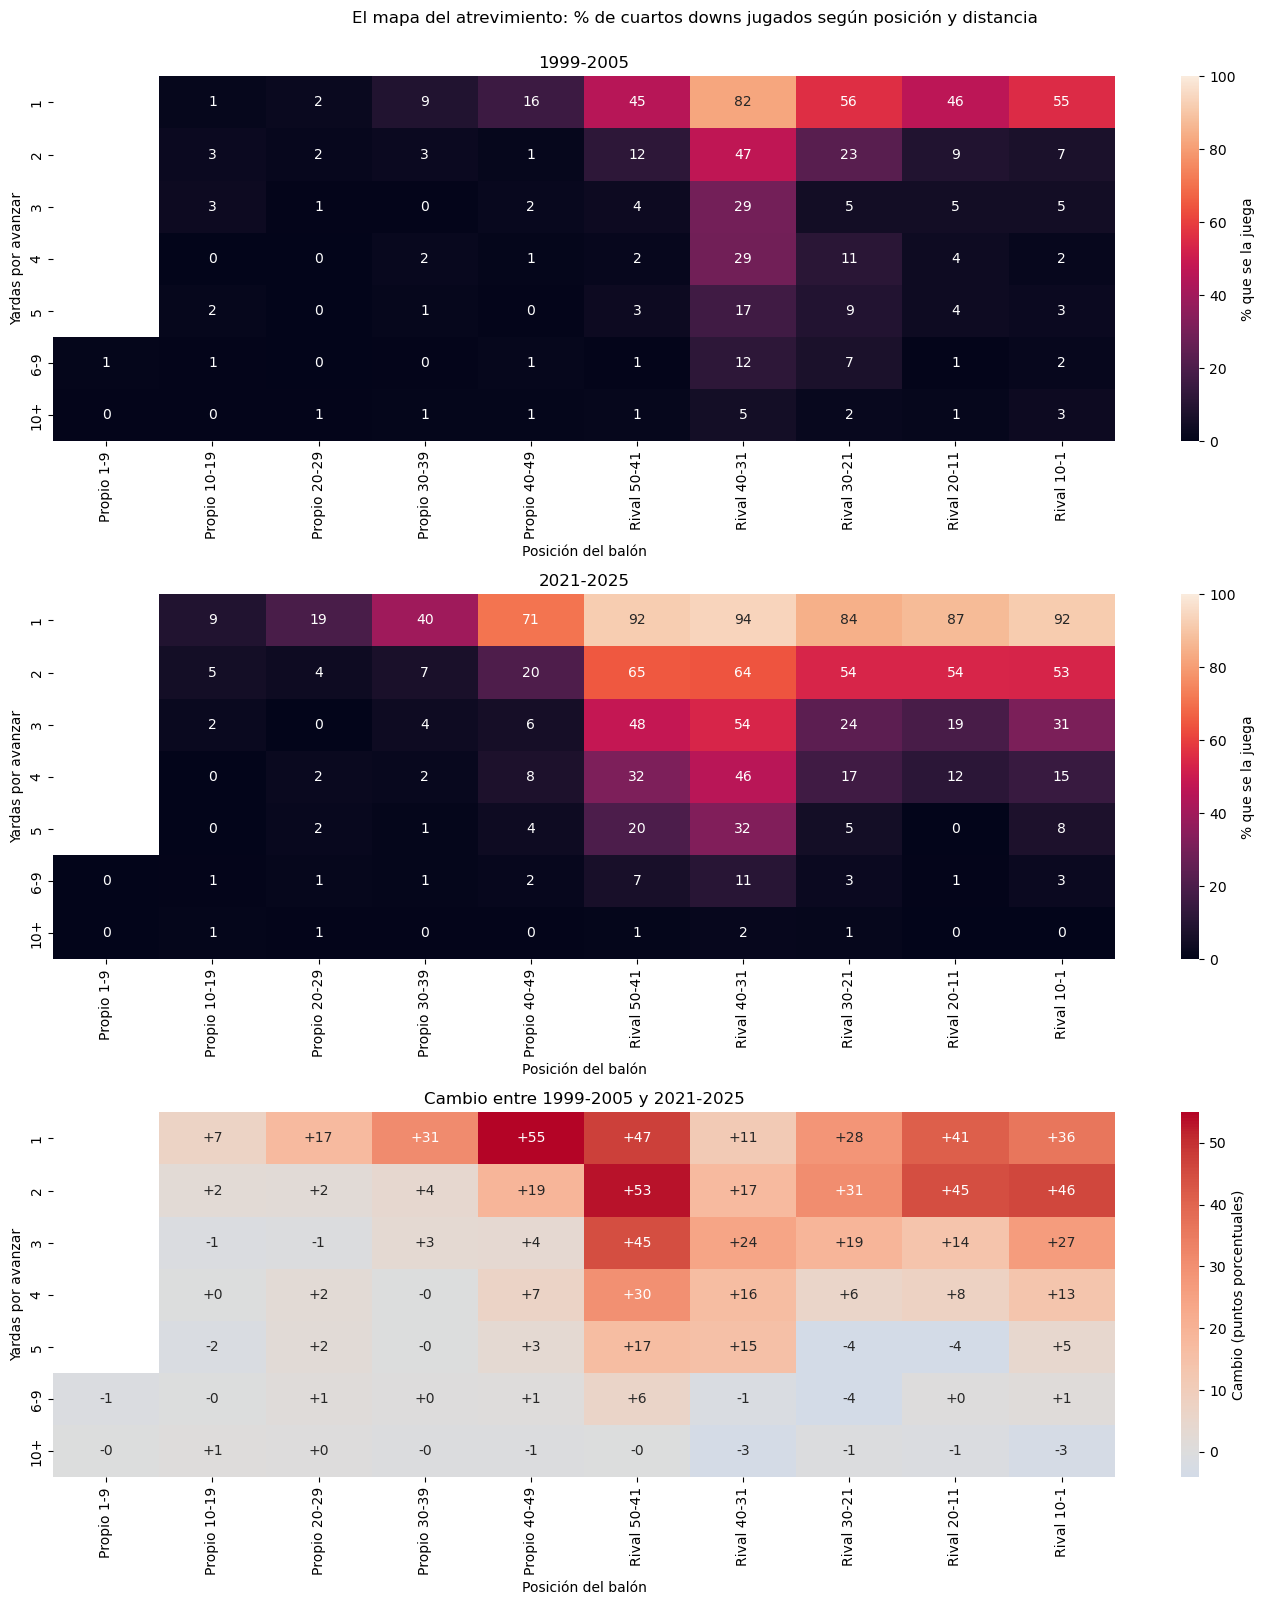

In [12]:
etiquetas_campo = ["Propio 1-9", "Propio 10-19", "Propio 20-29", "Propio 30-39", "Propio 40-49",
                   "Rival 50-41", "Rival 40-31", "Rival 30-21", "Rival 20-11", "Rival 10-1"]
cuarto["tramo_campo"] = pd.cut(100 - cuarto["yardline_100"], bins=range(0, 101, 10),
                               right=False, labels=etiquetas_campo)
cuarto["tramo_yardas"] = pd.cut(cuarto["ydstogo"], bins=[0, 1, 2, 3, 4, 5, 9, 99],
                                labels=["1", "2", "3", "4", "5", "6-9", "10+"])

def mapa_atrevimiento(inicio, fin, minimo=25):
    datos = cuarto[cuarto["season"].between(inicio, fin)]
    g = datos.groupby(["tramo_yardas", "tramo_campo"], observed=False)["se_la_juega"].agg(["mean", "size"])
    return g["mean"].where(g["size"] >= minimo).unstack() * 100

mapa_inicio = mapa_atrevimiento(1999, 2005)
mapa_hoy = mapa_atrevimiento(2021, 2025)
mapa_cambio = mapa_hoy - mapa_inicio

fig, axes = plt.subplots(3, 1, figsize=(14, 16))
sns.heatmap(mapa_inicio, annot=True, fmt=".0f", vmin=0, vmax=100, ax=axes[0],
            cbar_kws={"label": "% que se la juega"})
sns.heatmap(mapa_hoy, annot=True, fmt=".0f", vmin=0, vmax=100, ax=axes[1],
            cbar_kws={"label": "% que se la juega"})
sns.heatmap(mapa_cambio, annot=True, fmt="+.0f", cmap="coolwarm", center=0, ax=axes[2],
            cbar_kws={"label": "Cambio (puntos porcentuales)"})

titulos = ["1999-2005", "2021-2025", "Cambio entre 1999-2005 y 2021-2025"]
for ax, titulo in zip(axes, titulos):
    ax.set_title(titulo)
    ax.set_xlabel("Posición del balón")
    ax.set_ylabel("Yardas por avanzar")
plt.suptitle("El mapa del atrevimiento: % de cuartos downs jugados según posición y distancia", y=1.0)
plt.tight_layout()
plt.show()

In [13]:
# Valores de apoyo para el texto
for nombre, (inicio, fin) in {"1999-2005": (1999, 2005), "2021-2025": (2021, 2025)}.items():
    d = cuarto[cuarto["season"].between(inicio, fin) & cuarto["ydstogo"].isin([1, 2])]
    t = d.groupby(["zona", "ydstogo"], observed=True)["se_la_juega"].mean().unstack() * 100
    print(f"\n{nombre}:")
    print(t.round(1))


1999-2005:
ydstogo       1.0   2.0
zona                   
Rival 1-29   52.8  11.5
Rival 30-39  83.9  48.5
Medio campo  30.2   6.4
Propio 1-39   5.5   2.2

2021-2025:
ydstogo       1.0   2.0
zona                   
Rival 1-29   88.4  52.7
Rival 30-39  93.0  62.5
Medio campo  81.4  43.7
Propio 1-39  30.7   5.9


### Qué muestra el mapa

**El patrón de 1999-2005 es muy "conservador por defecto".** Solo hay una zona donde los equipos se la jugaban con frecuencia, la *tierra de nadie*, cerca de la yarda 35 del rival, donde un gol de campo era demasiado largo y despejar apenas ganaba terreno. Fuera de ahí, incluso en 4th & 1, la opción dominante era patear.

**El mapa de 2021-2025 es mucho más claro en toda la parte superior**, es decir, en las distancias cortas. Si agrupamos por zonas, el cambio en 4th & 1 y 4th & 2 es este:

| Zona | 4th & 1 · 1999-2005 | 4th & 1 · 2021-2025 | 4th & 2 · 1999-2005 | 4th & 2 · 2021-2025 |
|---|---|---|---|---|
| **Propio 1-39** | 5.5% | 30.7% | 2.2% | 5.9% |
| **Medio campo** | 30.2% | **81.4%** | 6.4% | **43.7%** |
| **Rival 30-39** | 83.9% | 93.0% | 48.5% | 62.5% |
| **Rival 1-29** | 52.8% | **88.4%** | 11.5% | **52.7%** |

El mapa de diferencias muestra dónde se concentró el cambio:

- **Medio campo:** en 4th & 1 los equipos pasaron de jugársela 3 de cada 10 veces a hacerlo **8 de cada 10**. Es justo la zona donde, como se vio en la gráfica anterior, despejar era claramente un error.
- **Cerca de la portería rival:** hoy, en 4th & 1 cerca de la zona de anotación, casi nadie se conforma con el gol de campo. En 4th & 2, se la juegan la mitad de las veces.
- **El propio campo sigue siendo territorio prudente.** Aunque en 4th & 1 se pasó del 5.5% al 30.7%, sigue siendo la zona donde más se patea, porque un fallo allí regala al rival una posición de anotación casi segura.
- **Las distancias largas no cambian.** La parte inferior del mapa (6 yardas o más) apenas se mueve: allí las probabilidades de conseguirlo son bajas y patear sigue siendo lo sensato.

En resumen, **la liga no se volvió "temeraria"**, sino que se volvió más agresiva exactamente donde los datos decían que debía hacerlo, y siguió siendo prudente donde la prudencia tiene sentido.

## 4. ¿Qué consecuencias tuvo? Qué pasa cuando llega el 4º down

La última pregunta del capítulo es qué cambió en el **resultado** de los cuartos downs. Para responderla se usa un **diagrama de Sankey** (o diagrama de flujo), que muestra cómo se reparten las decisiones y en qué terminan.

**Cómo leer el diagrama:**

- **A la izquierda**, las tres decisiones posibles, con el porcentaje de cuartos downs en que se tomó cada una.
- **A la derecha**, las tres consecuencias posibles:
  - **Primer down o TD:** el equipo se la jugó y lo consiguió, así que conserva el balón (o anota).
  - **3 puntos:** el gol de campo entró.
  - **Pierde el balón:** el despeje (que siempre entrega el balón al rival), el gol de campo fallado o la apuesta fallida.
- **El grosor de cada flujo** es proporcional al porcentaje de cuartos downs que siguen ese camino.

Se comparan las cinco primeras temporadas (1999-2003) con las cinco últimas (2021-2025), con el mismo filtro de partido normal del resto del capítulo. Al pasar el ratón por encima de un flujo se ve su porcentaje exacto.

In [14]:

convertido = (cuarto["fourth_down_converted"] == 1) | ((cuarto["touchdown"] == 1) & (cuarto["td_team"] == cuarto["posteam"]))
cuarto["consecuencia"] = np.select(
    [cuarto["se_la_juega"] & convertido,
     (cuarto["decision"] == "Gol de campo") & (cuarto["field_goal_result"] == "made")],
    ["Primer down o TD", "3 puntos"], default="Pierde el balón")

origenes = ["Jugársela", "Gol de campo", "Despeje"]
destinos = ["Primer down o TD", "3 puntos", "Pierde el balón"]
periodos_sankey = {"1999-2003": (1999, 2003), "2021-2025": (2021, 2025)}

fig = go.Figure()
for i, (nombre, (inicio, fin)) in enumerate(periodos_sankey.items()):
    d = cuarto[cuarto["season"].between(inicio, fin)]
    tabla_flujos = pd.crosstab(d["decision"], d["consecuencia"], normalize="all") * 100
    tabla_flujos = tabla_flujos.reindex(index=origenes, columns=destinos, fill_value=0)

    etiquetas = ([f"{o} ({tabla_flujos.loc[o].sum():.1f}%)" for o in origenes]
                 + [f"{c} ({tabla_flujos[c].sum():.1f}%)" for c in destinos])
    fuente, destino, valor = [], [], []
    for a, o in enumerate(origenes):
        for b, c in enumerate(destinos):
            if tabla_flujos.loc[o, c] > 0:
                fuente.append(a)
                destino.append(len(origenes) + b)
                valor.append(round(tabla_flujos.loc[o, c], 1))

    fig.add_trace(go.Sankey(domain={"x": [0, 0.45]} if i == 0 else {"x": [0.55, 1]},
                            node=dict(label=etiquetas, pad=20),
                            link=dict(source=fuente, target=destino, value=valor)))

fig.update_layout(title="Qué pasa cuando llega el 4º down: decisión y consecuencia (% de todos los cuartos downs)",
                  width=1200, height=550,
                  annotations=[dict(x=0.2, y=1.07, xref="paper", yref="paper", text="<b>1999-2003</b>", showarrow=False),
                               dict(x=0.8, y=1.07, xref="paper", yref="paper", text="<b>2021-2025</b>", showarrow=False)])
fig.show()

In [15]:
# Valores de apoyo para el texto
for nombre, (inicio, fin) in periodos_sankey.items():
    d = cuarto[cuarto["season"].between(inicio, fin)]
    print(f"\n{nombre} · % sobre todos los cuartos downs:")
    print((pd.crosstab(d["decision"], d["consecuencia"], normalize="all") * 100).round(1))
    print(f"{nombre} · % de conversión cuando se la juegan: {convertido[d.index][d['se_la_juega']].mean() * 100:.1f}%")
    print(f"{nombre} · % de goles de campo anotados: {(d.loc[d['decision'] == 'Gol de campo', 'field_goal_result'] == 'made').mean() * 100:.1f}%")


1999-2003 · % sobre todos los cuartos downs:
consecuencia  3 puntos  Pierde el balón  Primer down o TD
decision                                                 
Despeje            0.0             70.1               0.0
Gol de campo      18.1              4.8               0.0
Jugársela          0.0              3.0               3.9
1999-2003 · % de conversión cuando se la juegan: 56.2%
1999-2003 · % de goles de campo anotados: 78.9%

2021-2025 · % sobre todos los cuartos downs:
consecuencia  3 puntos  Pierde el balón  Primer down o TD
decision                                                 
Despeje            0.0             59.7               0.0
Gol de campo      21.5              3.4               0.0
Jugársela          0.0              6.1               9.2
2021-2025 · % de conversión cuando se la juegan: 60.0%
2021-2025 · % de goles de campo anotados: 86.3%


### Qué muestra el diagrama

Comparando los dos periodos, el cambio se resume así:

| | 1999-2003 | 2021-2025 |
|---|---|---|
| **Despeje** | 70.1% | 59.7% |
| **Gol de campo** | 22.9% | 24.9% |
| **Jugársela** | 6.9% | **15.3%** |
| → Primer down o TD | 3.9% | **9.2%** |
| → Pierde el balón tras jugársela | 3.0% | 6.1% |
| **Pierde el balón (total)** | 77.9% | **69.2%** |

**1. Jugársela pasa de ser algo raro a ser algo normal.** Su peso se multiplica por más de dos, del 6.9% al 15.3% de los cuartos downs, y lo hace sobre todo a costa del despeje, que cae diez puntos.

**2. Arriesgar más no significa fallar más.** Podría pensarse que, si los equipos se la juegan más a menudo, lo harán en situaciones peores y fracasarán más. No es así, la tasa de conversión cuando se la juegan se mantiene, e incluso sube ligeramente (del 56.2% al 60.0%). Los equipos han ampliado su atrevimiento sin perder eficacia, lo que confirma que había muchas situaciones favorables que antes se desperdiciaban.

**3. El resultado neto: menos posesiones regaladas.** A principios de siglo, casi 8 de cada 10 cuartos downs terminaban con el balón en manos del rival. Hoy son menos de 7 de cada 10. Mirado al revés, los cuartos downs que terminan con el equipo conservando el balón o sumando puntos pasan de un 22% a un 31%.

**4. Los goles de campo también funcionan mejor.** Dentro de los intentos de gol de campo, la proporción de anotados sube de un 79% a un 86%. Es un adelanto del siguiente capítulo.

## Conclusión del capítulo

El cuarto down es probablemente el ejemplo más claro de cómo los datos cambiaron el fútbol americano:

- **La evidencia existía desde principios de siglo.** Con los datos de 1999-2005 se comprueba que, en 4º y corto, jugársela era mejor que patear en casi todas las zonas del campo, tal como había señalado Romer.
- **La liga tardó más de una década en reaccionar**, y cuando lo hizo, a partir de 2018, el cambio fue rápido.
- **El cambio fue inteligente, no temerario**, ya que se concentró en las distancias cortas y en las zonas donde los datos lo recomendaban, y no afectó a las situaciones en las que patear sigue siendo lo correcto.
- **Las consecuencias son visibles:** menos balones regalados y más posesiones que continúan.

Pero el cuarto down no es solo una decisión del entrenador, sino que también depende de la otra opción disponible, **el gol de campo**. Y como se acaba de ver, los pateadores son hoy mucho más fiables que antes. Esa es la historia del siguiente capítulo.

---

# Capítulo 2. El alcance de los pateadores

## El contexto

Al final del capítulo anterior apareció un dato, que dentro de los intentos de gol de campo en cuarto down, la proporción de anotados pasó de un 79% a un 86%. Ese dato apunta a uno de los cambios más grandes, y menos comentados, de los últimos 25 años, que **los pateadores de la NFL son hoy mucho mejores que a principios de siglo** y los efectos que esto ha tenido.

Esto importa más de lo que parece. El gol de campo es una de las tres opciones en cada cuarto down, y su atractivo depende de la probabilidad de anotarlo. Si un pateador es fiable desde más lejos, la "zona de gol de campo" se amplía, y con ella cambia todo el cálculo de cuándo conviene patear, despejar o jugársela.

### Cómo se mide la distancia de un gol de campo

Los postes están al **fondo** de la zona de anotación, no en la línea de gol. Además, el balón se patea unas 7 yardas por detrás de la línea de golpeo, que es la distancia que necesita el equipo para centrar el balón y que el pateador tenga espacio. Por eso, la distancia de un gol de campo es aproximadamente:

> **distancia = yardas hasta la línea de gol + 10 (zona de anotación) + 7 (espacio para patear)**

Un balón situado en la yarda 30 del rival da lugar a un intento de unas 47 yardas.

## Las preguntas de este capítulo

1. **¿Cuánto han mejorado los pateadores?** ¿Desde qué distancia son fiables hoy, comparado con hace 25 años?
2. **¿A qué se debe la mejora?** Hay varias explicaciones posibles, y algunas se pueden comprobar con los datos:
   - ¿Hay más estadios **techados**, donde no hay viento ni lluvia?
   - ¿Influye el **clima**? ¿La mejora ocurre también con frío?
   - ¿Es un efecto de **selección**, es decir, que hoy solo se intentan las patadas "fáciles"?
   - ¿O simplemente **los pateadores son mejores**?

## Qué jugadas se analizan

Todos los intentos de gol de campo de temporada regular entre 1999 y 2025, sin el filtro de "partido normal" del capítulo anterior: aquí interesa la habilidad del pateador, que es la misma en cualquier momento del partido. Para comparar épocas, las 27 temporadas se dividen en **cuatro periodos de duración similar**: 1999-2005, 2006-2012, 2013-2019 y 2020-2025.

In [16]:
fg = reg[(reg["play_type"] == "field_goal")
         & reg["field_goal_result"].notna()
         & reg["kick_distance"].notna()].copy()
fg["anotado"] = (fg["field_goal_result"] == "made").astype(int)

ERAS = {"1999-2005": (1999, 2005), "2006-2012": (2006, 2012),
        "2013-2019": (2013, 2019), "2020-2025": (2020, 2025)}
fg["era"] = pd.cut(fg["season"], bins=[1998, 2005, 2012, 2019, 2025], labels=list(ERAS))
fg["bajo_techo"] = fg["roof"].isin(["dome", "closed"])

print(f"Intentos de gol de campo: {len(fg):,}")
print(fg.groupby("era", observed=True)["anotado"].agg(intentos="size", acierto="mean").round(3))

Intentos de gol de campo: 26,630
           intentos  acierto
era                         
1999-2005      6558    0.789
2006-2012      6823    0.828
2013-2019      6937    0.843
2020-2025      6312    0.850


## 1. ¿Cuánto han mejorado los pateadores?

La forma natural de medir la habilidad de los pateadores es ver **qué porcentaje de goles de campo se anotan según la distancia**. Para cada época, la gráfica muestra dos cosas:

- **Los puntos:** el porcentaje real de acierto en tramos de 3 yardas. Solo se dibujan los tramos con al menos 30 intentos, para no mostrar porcentajes basados en muy pocas patadas.
- **La línea:** una curva suave ajustada a todos los intentos de esa época mediante una **regresión logística**. Su ventaja es que aprovecha todos los intentos, incluidos los de distancias poco frecuentes, en lugar de depender de tramos sueltos con pocas patadas.

A partir de esa curva se calcula un dato muy fácil de interpretar: el **rango efectivo**, es decir, la distancia a la que la probabilidad de anotar cae al 80% (un pateador "fiable") y al 50% (una moneda al aire). Las líneas horizontales discontinuas marcan esos dos niveles.

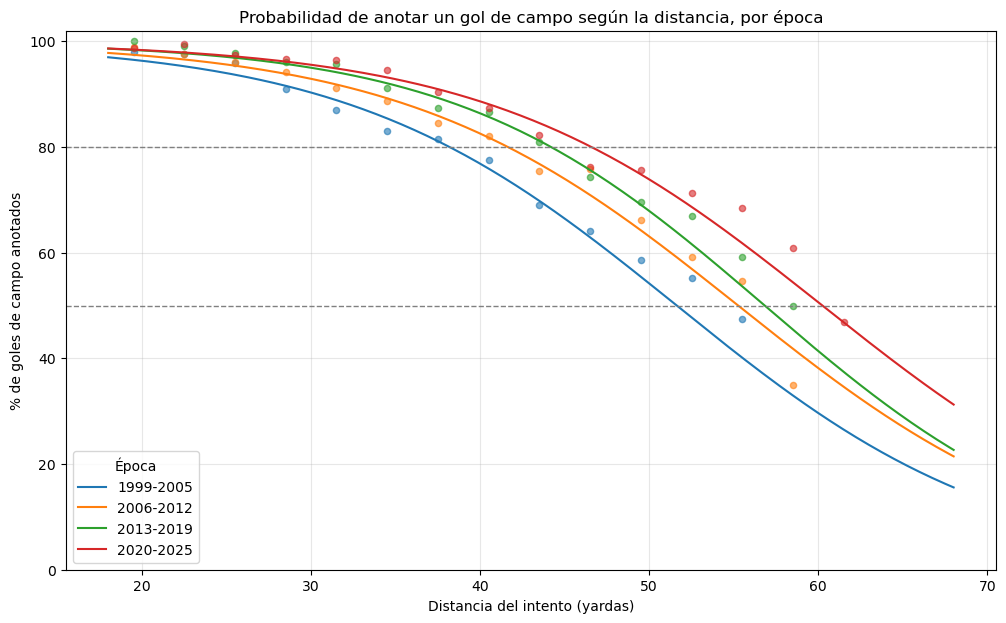

In [17]:
def ajustar_logistica(x, y, iteraciones=30):
    """Regresión logística simple: probabilidad de anotar en función de la distancia."""
    X = np.column_stack([np.ones_like(x), x])
    b = np.zeros(2)
    for _ in range(iteraciones):
        p = 1 / (1 + np.exp(-X @ b))
        W = p * (1 - p)
        b += np.linalg.solve(X.T @ (X * W[:, None]), X.T @ (y - p))
    return b

def probabilidad(b, distancia):
    return 1 / (1 + np.exp(-(b[0] + b[1] * distancia)))

def distancia_para(b, p):
    """Distancia a la que la probabilidad de anotar es p."""
    return (np.log(p / (1 - p)) - b[0]) / b[1]

distancias = np.linspace(18, 68, 200)
coeficientes = {}

fig, ax = plt.subplots(figsize=(12, 7))
for era in ERAS:
    d = fg[(fg["era"] == era) & fg["kick_distance"].between(18, 70)]
    b = ajustar_logistica(d["kick_distance"].values.astype(float), d["anotado"].values.astype(float))
    coeficientes[era] = b
    linea, = ax.plot(distancias, probabilidad(b, distancias) * 100, label=era)
    tramos = d.groupby((d["kick_distance"] // 3) * 3 + 1.5)["anotado"].agg(["mean", "size"])
    tramos = tramos[tramos["size"] >= 30]
    ax.scatter(tramos.index, tramos["mean"] * 100, color=linea.get_color(), s=20, alpha=0.6)

ax.axhline(80, color="gray", linestyle="--", linewidth=1)
ax.axhline(50, color="gray", linestyle="--", linewidth=1)
ax.set_title("Probabilidad de anotar un gol de campo según la distancia, por época")
ax.set_xlabel("Distancia del intento (yardas)")
ax.set_ylabel("% de goles de campo anotados")
ax.set_ylim(0, 102)
ax.legend(title="Época")
ax.grid(True, alpha=0.3)
plt.show()

In [18]:
# Valores de apoyo para el texto
fg["tramo"] = pd.cut(fg["kick_distance"], bins=[0, 29, 39, 49, 54, 59, 80],
                     labels=["menos de 30", "30-39", "40-49", "50-54", "55-59", "60 o más"])
acierto = fg.groupby(["tramo", "era"], observed=True)["anotado"].agg(["mean", "size"])
print("% de acierto por tramo y época:")
print((acierto["mean"].unstack() * 100).round(1))
print("\nNúmero de intentos:")
print(acierto["size"].unstack())

print("\nRango efectivo (yardas):")
for era, b in coeficientes.items():
    print(f"  {era}: 80% de acierto hasta {distancia_para(b, 0.8):.1f} yd · 50% de acierto a {distancia_para(b, 0.5):.1f} yd")

% de acierto por tramo y época:
era          1999-2005  2006-2012  2013-2019  2020-2025
tramo                                                  
menos de 30       95.1       96.4       97.8       97.8
30-39             82.8       87.7       90.9       93.3
40-49             67.6       74.8       77.5       79.9
50-54             57.1       60.4       66.8       72.9
55-59             28.1       45.7       54.5       62.2
60 o más           0.0       23.5       27.0       39.7

Número de intentos:
era          1999-2005  2006-2012  2013-2019  2020-2025
tramo                                                  
menos de 30       1934       1982       1727       1391
30-39             1958       2012       2029       1768
40-49             2084       2040       2123       1804
50-54              503        639        819        882
55-59               64        116        202        389
60 o más            15         34         37         78

Rango efectivo (yardas):
  1999-2005: 80% de acier

### Qué muestra la gráfica

**Las curvas se desplazan hacia la derecha, época tras época.** Cada generación de pateadores es fiable desde más lejos que la anterior. El rango efectivo lo resume:

| Época | Distancia con 80% de acierto | Distancia con 50% de acierto |
|---|---|---|
| 1999-2005 | 38.2 yardas | 51.6 yardas |
| 2006-2012 | 41.6 yardas | 55.3 yardas |
| 2013-2019 | 44.2 yardas | 56.8 yardas |
| 2020-2025 | **46.6 yardas** | **60.2 yardas** |

En 25 años, **el alcance de los pateadores ha crecido unas 8 o 9 yardas**. Una patada que a principios de siglo era una moneda al aire (unas 52 yardas) hoy se anota en torno a dos de cada tres veces.

La mejora no está solo en las patadas largas, sino en **todas las distancias**:

| Distancia | 1999-2005 | 2020-2025 |
|---|---|---|
| 30-39 yardas | 82.8% | 93.3% |
| 40-49 yardas | 67.6% | 79.9% |
| 50-54 yardas | 57.1% | 72.9% |
| 55-59 yardas | 28.1% | **62.2%** |
| 60 o más | 0 de 15 | **39.7%** (de 78) |

El caso más llamativo son las patadas de 55 a 59 yardas: hoy se anotan **casi con la misma frecuencia (62%) que las de 40 a 49 yardas a principios de siglo (68%)**. Y las patadas de 60 yardas o más, que entre 1999 y 2005 no se anotó ninguna de las 15 intentadas, hoy entran en cuatro de cada diez intentos.

La pregunta inevitable es **por qué**.

## 2. ¿A qué se debe la mejora?

Hay varias explicaciones posibles, y tres de ellas se pueden poner a prueba con los datos. La siguiente figura tiene un panel para cada una:

**Panel izquierdo: ¿son los estadios techados?** En un estadio cerrado no hay viento, lluvia ni frío, y las patadas son más fáciles. Si en los últimos años se han jugado más partidos bajo techo, eso podría explicar parte de la mejora. Para comprobarlo, se calcula el rango efectivo (distancia con 50% de acierto) por separado para las patadas **bajo techo** y **al aire libre**. *Si la mejora se debiera a los estadios, solo debería aparecer en la línea de "bajo techo"*, o al menos ser mucho mayor ahí.

**Panel central: ¿es el clima?** Si la mejora fuera cosa de unas condiciones más favorables, no debería aparecer en los días fríos. Se mira el acierto en patadas de **40 a 55 yardas al aire libre**, separado por **temperatura** y por época.

**Panel derecho: ¿es un efecto de selección?** Si hoy los entrenadores solo intentaran las patadas "seguras", el acierto subiría sin que los pateadores fueran mejores. Pero entonces debería haber **menos** intentos largos, no más. El panel muestra, para cada temporada, cuántos intentos de **50 yardas o más** hay por partido (barras) y qué porcentaje se anota (línea).

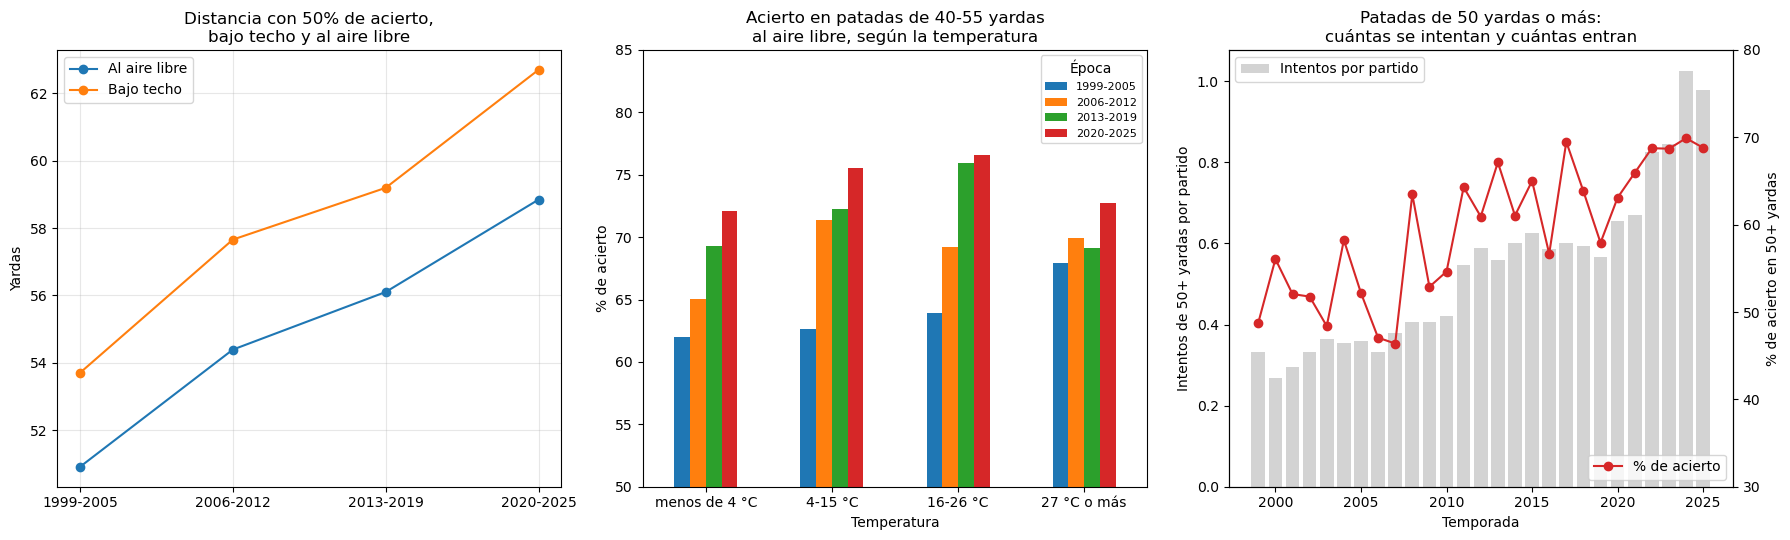

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel 1
filas = []
for era in ERAS:
    for techo, nombre in [(True, "Bajo techo"), (False, "Al aire libre")]:
        d = fg[(fg["era"] == era) & (fg["bajo_techo"] == techo) & fg["kick_distance"].between(18, 70)]
        b = ajustar_logistica(d["kick_distance"].values.astype(float), d["anotado"].values.astype(float))
        filas.append({"era": era, "estadio": nombre, "d50": distancia_para(b, 0.5), "intentos": len(d)})
rango_techo = pd.DataFrame(filas)
for nombre, d in rango_techo.groupby("estadio"):
    axes[0].plot(d["era"], d["d50"], marker="o", label=nombre)
axes[0].set_title("Distancia con 50% de acierto,\nbajo techo y al aire libre")
axes[0].set_ylabel("Yardas")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2
aire = fg[~fg["bajo_techo"] & fg["temp"].notna() & fg["kick_distance"].between(40, 55)].copy()
aire["temperatura"] = pd.cut(aire["temp"], bins=[-30, 39, 59, 79, 120],
                             labels=["menos de 4 °C", "4-15 °C", "16-26 °C", "27 °C o más"])
por_temp = aire.groupby(["temperatura", "era"], observed=True)["anotado"].mean().unstack() * 100
por_temp.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Acierto en patadas de 40-55 yardas\nal aire libre, según la temperatura")
axes[1].set_xlabel("Temperatura")
axes[1].set_ylabel("% de acierto")
axes[1].set_ylim(50, 85)
axes[1].legend(title="Época", fontsize=8)

# Panel 3
largas = fg[fg["kick_distance"] >= 50].groupby("season")["anotado"].agg(intentos="size", acierto="mean")
partidos_temporada = reg.groupby("season")["game_id"].nunique()
largas["por_partido"] = largas["intentos"] / partidos_temporada
axes[2].bar(largas.index, largas["por_partido"], color="lightgray", label="Intentos por partido")
axes[2].set_ylabel("Intentos de 50+ yardas por partido")
axes[2].set_xlabel("Temporada")
eje2 = axes[2].twinx()
eje2.plot(largas.index, largas["acierto"] * 100, marker="o", color="tab:red", label="% de acierto")
eje2.set_ylabel("% de acierto en 50+ yardas")
eje2.set_ylim(30, 80)
axes[2].set_title("Patadas de 50 yardas o más:\ncuántas se intentan y cuántas entran")
axes[2].legend(loc="upper left")
eje2.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [20]:
# Valores de apoyo para el texto
print("Rango efectivo (50%) por tipo de estadio:")
print(rango_techo.pivot(index="era", columns="estadio", values="d50").round(1))
print("\nIntentos por tipo de estadio:")
print(rango_techo.pivot(index="era", columns="estadio", values="intentos"))
print("\n% de acierto 40-55 yardas al aire libre por temperatura:")
print(por_temp.round(1))
print("\nPatadas de 50+ yardas:")
print(largas[["intentos", "por_partido", "acierto"]].round(3))

Rango efectivo (50%) por tipo de estadio:
estadio    Al aire libre  Bajo techo
era                                 
1999-2005           50.9        53.7
2006-2012           54.4        57.7
2013-2019           56.1        59.2
2020-2025           58.8        62.7

Intentos por tipo de estadio:
estadio    Al aire libre  Bajo techo
era                                 
1999-2005           5233        1325
2006-2012           5158        1664
2013-2019           5276        1660
2020-2025           4154        2158

% de acierto 40-55 yardas al aire libre por temperatura:
era            1999-2005  2006-2012  2013-2019  2020-2025
temperatura                                              
menos de 4 °C       62.0       65.1       69.3       72.1
4-15 °C             62.6       71.4       72.3       75.6
16-26 °C            63.9       69.2       76.0       76.6
27 °C o más         68.0       69.9       69.1       72.7

Patadas de 50+ yardas:
        intentos  por_partido  acierto
season        

### Qué muestra la figura

**1. Los estadios techados no explican la mejora.** Bajo techo se patea mejor, como era de esperar, y el rango efectivo es entre 2 y 4 yardas mayor que al aire libre en todas las épocas. Pero **la mejora aparece en ambas líneas casi por igual**:

| Distancia con 50% de acierto | 1999-2005 | 2020-2025 | Mejora |
|---|---|---|---|
| Bajo techo | 53.7 yd | 62.7 yd | +9.0 yd |
| Al aire libre | 50.9 yd | 58.8 yd | +7.9 yd |

Es cierto que hoy hay más patadas bajo techo (pasan de un 20% a un 34% de los intentos), y eso empuja un poco hacia arriba el promedio de la liga. Pero aunque se compare techo con techo y aire libre con aire libre, los pateadores de hoy llegan unas 8 o 9 yardas más lejos.

**2. El clima tampoco lo explica.** La mejora aparece en todas las temperaturas, **incluido el frío**. En días por debajo de 4 °C, el acierto en patadas de 40 a 55 yardas al aire libre pasó del 62.0% (1999-2005) al 72.1% (2020-2025). Los pateadores de hoy en un día de frío aciertan más que los de hace 25 años en un día templado.

**3. No es un efecto de selección; de hecho, ocurre lo contrario.** Si la mejora se debiera a que hoy solo se intentan las patadas fáciles, deberían intentarse menos patadas largas. Pero el número de intentos de 50 yardas o más por partido **se ha triplicado**: de unos 0.33 por partido en 1999 a cerca de 1 por partido en 2024 y 2025. Y aun así, el porcentaje de acierto en esas patadas **subió**, del 49% al 69%. Normalmente, cuando se intentan más cosas difíciles, el porcentaje de éxito baja. Que haya subido es una señal muy fuerte de que la mejora es real.

Una última comprobación refuerza esta conclusión, es que la mejora también aparece en las **distancias medias**, como las patadas de 30 a 39 yardas (del 82.8% al 93.3%). En esas distancias, los equipos intentan prácticamente todas las patadas posibles, así que ahí no puede haber efecto de selección.

### Entonces, ¿a qué se debe?

Descartadas las explicaciones "externas" (estadios, clima y selección), la explicación más probable es la más directa, que **los pateadores son mejores**. Los datos de este trabajo no permiten saber exactamente por qué, pero las causas más citadas son la **especialización** (preparadores dedicados exclusivamente a los pateadores, entrenamiento técnico específico desde edades tempranas) y una **competencia más dura** por cada puesto, que solo deja llegar a la NFL a los mejores. Son hipótesis razonables, aunque quedan fuera del alcance de estos datos.

## Conclusión del capítulo

- **El alcance de los pateadores ha crecido unas 8 o 9 yardas en 25 años**, y la mejora se ve en todas las distancias.
- **No se debe a factores externos:** aparece bajo techo y al aire libre, con frío y con calor, y a pesar de que hoy se intentan muchas más patadas largas.
- **Tiene consecuencias estratégicas:** con pateadores más fiables, el gol de campo es una opción más atractiva desde más lejos, lo que cambia el cálculo del cuarto down que se vio en el Capítulo 1.

Pero que los pateadores fueran tan buenos también tuvo un efecto que la liga no quería. A principios de siglo, el **punto extra** se anotaba en el 99% de los casos y eso hacia que fuera una jugada prácticamente automática, sin ninguna emoción. En 2015, la liga decidió cambiar la regla. Ese cambio, junto con la transformación de la patada de salida, es el tema del siguiente capítulo.

---

# Capítulo 3. Cambio de reglas

## El contexto: por qué cambian las reglas

Los dos capítulos anteriores mostraron cambios que vinieron **desde dentro del juego**. Los entrenadores que aprendieron a decidir mejor y pateadores que mejoraron su técnica. Este capítulo trata de cambios que vinieron **desde fuera**: decisiones de la propia liga, que modificó las reglas y como consecuencia como se juega el juego.

La NFL cambia su reglamento casi todos los años, normalmente por una de dos razones:

1. **La seguridad de los jugadores.** El fútbol americano es un deporte de contacto, y algunas jugadas son especialmente peligrosas. Cuando la liga detecta que una jugada concentra demasiadas lesiones, intenta cambiarla.
2. **El espectáculo.** Si una jugada se vuelve aburrida o predecible, la liga puede modificarla para devolverle interés.

Este capítulo analiza dos jugadas que se transformaron por cada uno de esos motivos: **la patada de salida**, reformada varias veces por seguridad, y **el punto extra**, reformado en 2015 porque había dejado de tener emoción. En ambos casos, la pregunta es la misma: **¿qué consecuencias tuvo cada cambio?** Y, en particular, ¿se consiguió lo que la liga buscaba?

## Parte A. La patada de salida, reescrita una y otra vez

### Por qué la liga quería cambiarla

La patada de salida (*kickoff*) reinicia el juego al comienzo de cada mitad y después de cada anotación. Un equipo patea el balón desde su propio campo y el otro intenta devolverlo (*retornarlo*) lo más lejos posible. Durante el regreso, los jugadores de ambos equipos corren unos contra otros a toda velocidad desde muchas de yardas de distancia, y los choques son mucho más violentos que en una jugada normal. Los estudios de la propia liga la señalaron como **la jugada con más conmociones cerebrales del juego**.

La forma más sencilla de reducir esos choques es que haya **menos regresos**. Por eso, durante años, la liga intentó aumentar los **touchbacks**, porque si el balón llega a la zona de anotación y el receptor no lo devuelve, la jugada termina sin contacto y el ataque empieza en un punto fijo del campo.

### Los cambios de regla entre 1999 y 2025

| Temporada | Cambio | Objetivo |
|---|---|---|
| **1999-2010** | La patada se hace desde la propia yarda 30. El touchback coloca el balón en la yarda 20. | (Regla de partida) |
| **2011** | La patada se adelanta a la **yarda 35**. | Que más patadas lleguen a la zona de anotación y haya más touchbacks. |
| **2016** | El touchback pasa a colocar el balón en la **yarda 25**. | Premiar al receptor que no retorna el balón. |
| **2018** | Nueva **formación** obligatoria: los jugadores del equipo que patea no pueden tomar carrera, entre otros cambios. | Reducir la velocidad de los choques. |
| **2023** | Un **fair catch** (recepción sin regreso) dentro de la yarda 25 se convierte en touchback a la 25. | Dar otra forma de evitar el regreso. |
| **2024** | **"Dynamic kickoff":** una formación completamente nueva, inspirada en otras ligas, con los jugadores de ambos equipos colocados cerca unos de otros para evitar las carreras largas. El touchback pasa a la **yarda 30**. | **Recuperar los regresos**, pero de forma más segura. |
| **2025** | El touchback pasa a la **yarda 35**. | Hacer menos atractivo el touchback, para que haya todavía más regresos. |

Hay un giro importante en la historia, **durante más de una década, la liga intentó eliminar los regresos; sin embargo, a partir de 2024 intentó recuperarlos**. Había conseguido que la jugada fuera más segura, pero a costa de convertirla en un trámite aburrido. El *dynamic kickoff* fue el intento de tener ambas cosas: regresos y seguridad.

### Una nota sobre los datos

La forma de terminar de cada patada se identifica con las variables de nflfastR (touchback, fuera del campo, fair catch, balón derribado), salvo las **patadas cortas intencionales** (*onside kicks*), que se identifican buscando la palabra "onside" en la descripción de la jugada. Todo lo que no cae en ninguna de esas categorías se considera **retornado**.

In [21]:
ko = reg[reg["play_type"] == "kickoff"].copy()

es_onside = ko["desc"].fillna("").str.contains("onside", case=False)
ko["resultado"] = np.select(
    [es_onside,
     ko["touchback"].fillna(0) == 1,
     ko["kickoff_out_of_bounds"].fillna(0) == 1,
     (ko["kickoff_fair_catch"].fillna(0) == 1) | (ko["kickoff_downed"].fillna(0) == 1)],
    ["Onside", "Touchback", "Fuera del campo", "Fair catch o derribada"],
    default="Retornada")

print(f"Patadas de salida: {len(ko):,}")

k23 = ko[ko["season"] == 2023]
print("\n2023 · reparto de resultados:")
print((k23["resultado"].value_counts(normalize=True) * 100).round(1))
print(f"2023 · % de patadas cuya descripción menciona 'fair catch': "
      f"{k23['desc'].str.contains('fair catch', case=False, na=False).mean() * 100:.1f}%")

Patadas de salida: 69,513

2023 · reparto de resultados:
resultado
Touchback                 73.0
Retornada                 21.7
Fair catch o derribada     3.4
Onside                     1.5
Fuera del campo            0.4
Name: proportion, dtype: float64
2023 · % de patadas cuya descripción menciona 'fair catch': 3.4%


### ¿Qué pasaba con cada patada de salida bajo cada regla?

Para comparar los distintos periodos se usan **gráficos de waffle** (*waffle charts*). Cada gráfico tiene 100 cuadrados, y **cada cuadrado representa el 1% de las patadas de salida** de ese periodo. El color indica cómo terminó la patada:

- **Retornada:** el receptor devolvió el balón (la jugada peligrosa).
- **Touchback:** el balón llegó a la zona de anotación y no se devolvió.
- **Fair catch o derribada:** el receptor atrapó el balón sin intentar devolverlo, o el balón se detuvo sin regreso.
- **Fuera del campo:** la patada salió por la banda (es una falta del equipo que patea).
- **Onside:** patada corta intencional para intentar recuperar el balón.

Se muestran seis periodos, uno por cada régimen de reglas relevante. Los tres últimos son de una sola temporada, porque las reglas cambiaron cada año.

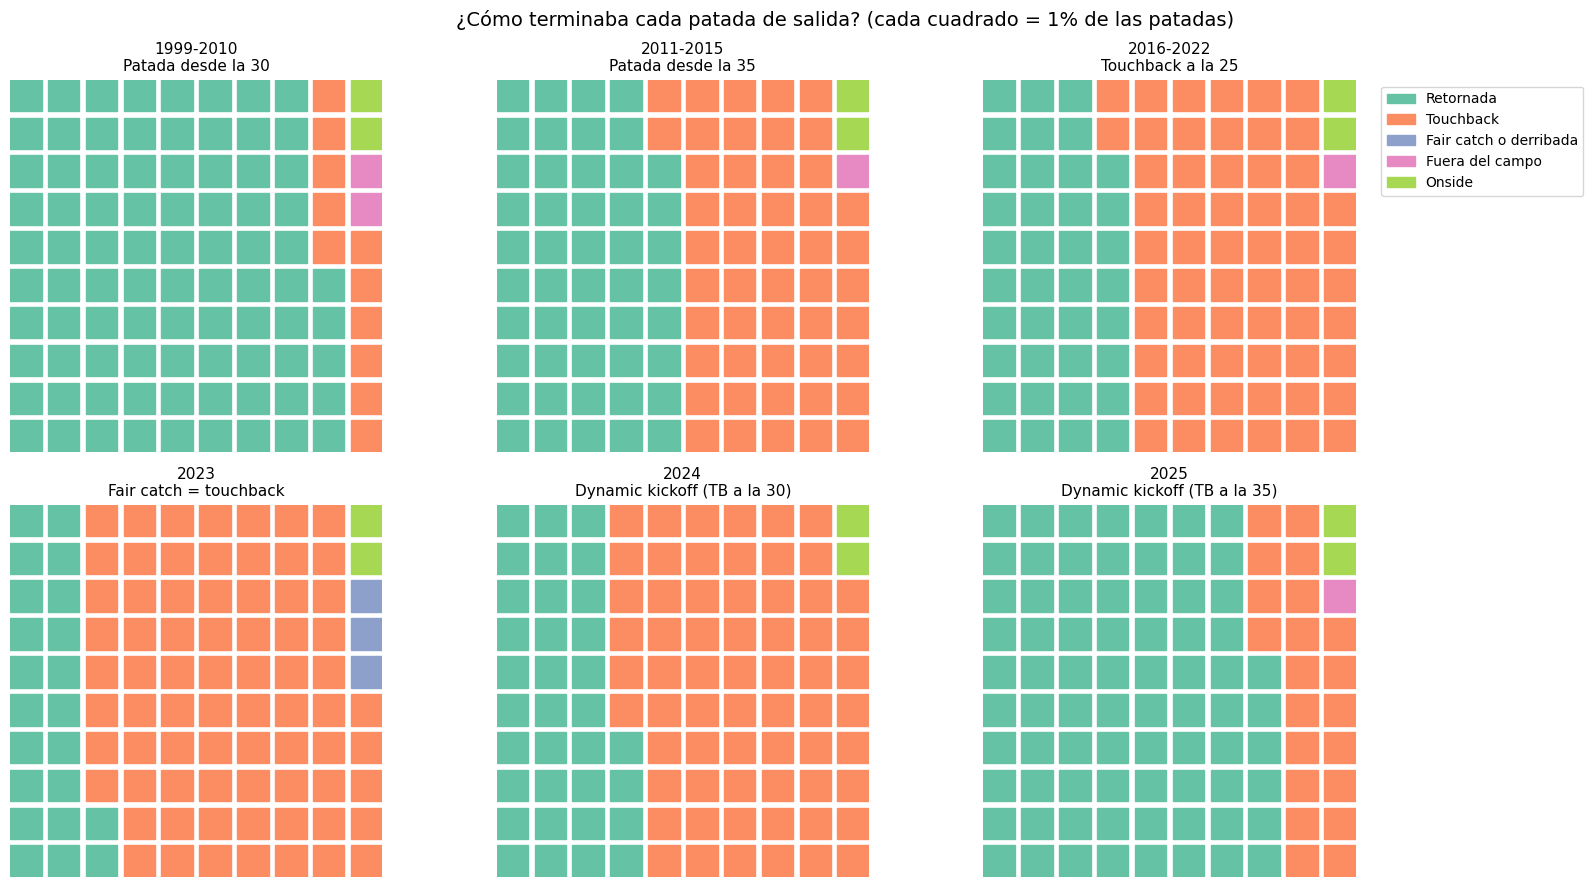

In [22]:
def repartir_100(porcentajes):
    cuadrados = np.floor(porcentajes).astype(int)
    faltan = 100 - cuadrados.sum()
    decimales = (porcentajes - cuadrados).sort_values(ascending=False)
    cuadrados[decimales.index[:faltan]] += 1
    return cuadrados

REGIMENES = {
    "1999-2010\nPatada desde la 30": (1999, 2010),
    "2011-2015\nPatada desde la 35": (2011, 2015),
    "2016-2022\nTouchback a la 25": (2016, 2022),
    "2023\nFair catch = touchback": (2023, 2023),
    "2024\nDynamic kickoff (TB a la 30)": (2024, 2024),
    "2025\nDynamic kickoff (TB a la 35)": (2025, 2025),
}
categorias = ["Retornada", "Touchback", "Fair catch o derribada", "Fuera del campo", "Onside"]

graficos = {}
for i, (nombre, (inicio, fin)) in enumerate(REGIMENES.items()):
    d = ko[ko["season"].between(inicio, fin)]
    porcentajes = d["resultado"].value_counts(normalize=True).reindex(categorias, fill_value=0) * 100
    graficos[231 + i] = {"values": repartir_100(porcentajes).tolist(),
                         "title": {"label": nombre, "fontsize": 11}}
graficos[233]["labels"] = categorias
graficos[233]["legend"] = {"loc": "upper left", "bbox_to_anchor": (1.05, 1)}

fig = plt.figure(FigureClass=Waffle, plots=graficos, rows=10, columns=10, figsize=(17, 9))
fig.suptitle("¿Cómo terminaba cada patada de salida? (cada cuadrado = 1% de las patadas)", fontsize=14)
plt.show()

* Como cada gráfico tiene exactamente 100 cuadrados y los porcentajes tienen decimales, algunas categorías pequeñas pueden mostrar un cuadrado más o uno menos que su porcentaje exacto. Los porcentajes precisos se imprimen en la tabla siguiente.

In [23]:
# Valores de apoyo para el texto
filas = {}
for nombre, (inicio, fin) in REGIMENES.items():
    d = ko[ko["season"].between(inicio, fin)]
    filas[nombre.replace("\n", " · ")] = d["resultado"].value_counts(normalize=True).reindex(categorias, fill_value=0) * 100
print(pd.DataFrame(filas).T.round(1))

resultado                            Retornada  Touchback  \
1999-2010 · Patada desde la 30            84.7       11.2   
2011-2015 · Patada desde la 35            48.4       48.5   
2016-2022 · Touchback a la 25             37.9       59.2   
2023 · Fair catch = touchback             21.7       73.0   
2024 · Dynamic kickoff (TB a la 30)       33.5       64.2   
2025 · Dynamic kickoff (TB a la 35)       76.2       20.7   

resultado                            Fair catch o derribada  Fuera del campo  \
1999-2010 · Patada desde la 30                          0.3              1.5   
2011-2015 · Patada desde la 35                          0.1              0.6   
2016-2022 · Touchback a la 25                           0.0              0.6   
2023 · Fair catch = touchback                           3.4              0.4   
2024 · Dynamic kickoff (TB a la 30)                     0.0              0.5   
2025 · Dynamic kickoff (TB a la 35)                     0.0              1.3   

resultado  

### Qué muestran los gráficos

**1999-2010: la patada de salida era, casi siempre, un regreso.** El 85% de las patadas se devolvían y solo el 11% terminaban en touchback. Es decir, en casi todas las patadas de salida había una carrera a toda velocidad con choques entre jugadores.

**2011-2015: un solo cambio partió la jugada por la mitad.** Al adelantar la patada cinco yardas, a la 35, los pateadores empezaron a mandar el balón a la zona de anotación con mucha más facilidad. Los regresos cayeron al 48% y los touchbacks subieron al 48.5%. Con una sola regla, la mitad de las patadas de salida dejaron de tener choques.

**2016-2022: el touchback a la 25 reforzó la tendencia.** Al hacer más atractivo no devolver el balón, los regresos siguieron bajando, hasta quedar por debajo del 40% de las patadas.

**2023: el mínimo histórico.** Al permitir que un fair catch dentro de la yarda 25 contara como touchback, los regresos se desplomaron hasta el **21.7%**, el valor más bajo de toda la serie. En los datos, ese descenso aparece casi entero como **touchbacks**, que suben del 59% al **73%**, mientras que las recepciones registradas expresamente como fair catch son solo el 3.4%. Esto es coherente con que la regla convierte esos fair catch en touchback, aunque los datos no permiten distinguir exactamente cuántas de esas jugadas fueron de cada tipo. En cualquier caso, la jugada estaba prácticamente desapareciendo.

**2024: el primer intento de recuperar los regresos.** El *dynamic kickoff* cambió por completo la formación, pero los regresos solo subieron hasta el **33.5%**. Para entenderlo hay que mirar la decisión del **equipo que patea**, ya que puede mandar el balón a la zona de anotación (y entonces el rival puede quedarse con el touchback) o a la "zona de aterrizaje", entre la yarda 20 y la línea de gol, donde el balón tiene que devolverse. Con el touchback en la yarda 30, dar un touchback dejaba al rival más o menos donde lo habría dejado un regreso normal, pero sin el riesgo de un regreso largo. Por eso muchos equipos siguieron prefiriendo mandar el balón a la zona de anotación, y los touchbacks siguieron siendo mayoría.

**2025: el ajuste que sí funcionó.** Al llevar el touchback a la yarda 35, regalarle el touchback al rival pasó a ser la peor opción para el equipo que patea porque le daba cinco yardas más que un regreso típico. Como consecuencia los equipos empezaron a patear a la zona de aterrizaje para forzar el regreso, y los regresos se dispararon hasta el **76.2%** de las patadas. Prácticamente se volvió al nivel de principios de siglo, pero con una formación diseñada para que los choques sean menos violentos.

La lectura de conjunto es clara, ya que **cada cambio de regla tuvo un efecto inmediato y fácil de ver en los datos**. Los equipos responden a los incentivos: cuando la liga hizo más valioso el touchback, hubo más touchbacks; cuando lo hizo menos valioso, volvieron los regresos.

Pero estos cambios tuvieron también una consecuencia que va más allá de la seguridad, y que la siguiente gráfica permite ver: **dónde empieza el ataque después de cada patada**.

### La consecuencia menos visible: dónde empieza el ataque

Cada patada de salida termina con el balón en algún punto del campo, desde donde el equipo receptor empieza a atacar. Ese punto importa mucho, como ya vimos en el Capítulo 0, empezar en la propia yarda 20 o en la 30 cambia los puntos esperados del drive.

Para medirlo, se busca la **primera jugada de ataque** después de cada patada de salida y se registra su posición (en yardas desde la propia línea de gol). Se excluyen las patadas cortas intencionales, las que recuperó el propio equipo que patea y los regresos que terminaron en touchdown, porque en esos casos no hay un "punto de inicio" comparable.

La figura tiene dos paneles: **arriba**, la posición media de inicio del ataque en cada temporada; **abajo**, el porcentaje de patadas retornadas. Las líneas verticales punteadas marcan los cambios de regla.

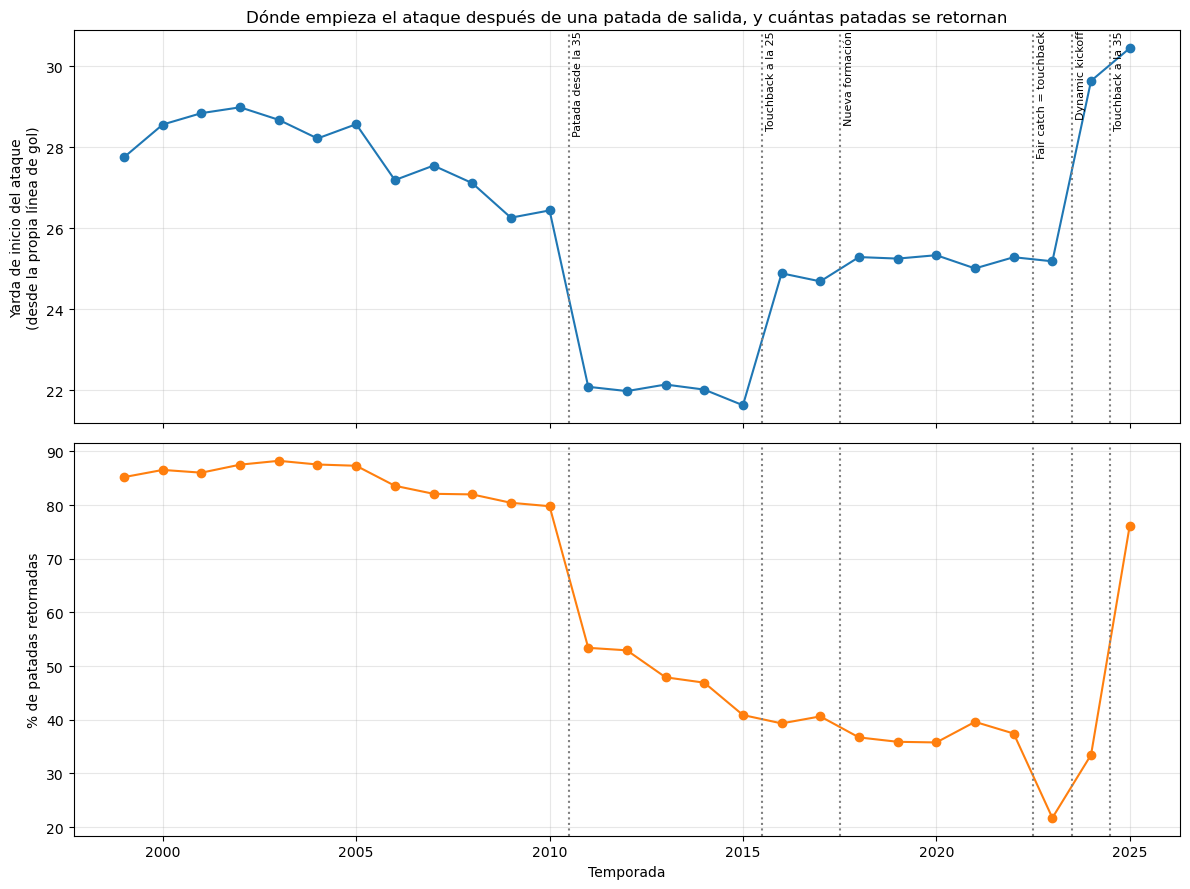

In [24]:
JUGADAS_ATAQUE = ["pass", "run", "punt", "field_goal", "qb_kneel", "qb_spike"]
es_ataque = reg["play_type"].isin(JUGADAS_ATAQUE)
es_kickoff = reg["play_type"] == "kickoff"
partido = reg["game_id"]

evento = pd.Series(np.where(es_ataque, "A", np.where(es_kickoff, "K", None)), index=reg.index, dtype=object)
yarda_ataque = (100 - reg["yardline_100"]).where(es_ataque)
siguiente_evento = evento.groupby(partido).shift(-1).groupby(partido).bfill()
siguiente_yarda = yarda_ataque.groupby(partido).shift(-1).groupby(partido).bfill()

inicio_ataque = ko.assign(inicio=siguiente_yarda[ko.index], siguiente=siguiente_evento[ko.index])
inicio_ataque = inicio_ataque[(inicio_ataque["siguiente"] == "A")
                              & inicio_ataque["inicio"].notna()
                              & (inicio_ataque["resultado"] != "Onside")
                              & (inicio_ataque["own_kickoff_recovery"].fillna(0) == 0)
                              & (inicio_ataque["return_touchdown"].fillna(0) == 0)]

inicio_medio = inicio_ataque.groupby("season")["inicio"].mean()
pct_retornadas = ko.groupby("season")["resultado"].apply(lambda x: (x == "Retornada").mean() * 100)

cambios_regla = {2011: "Patada desde la 35", 2016: "Touchback a la 25", 2018: "Nueva formación",
                 2023: "Fair catch = touchback", 2024: "Dynamic kickoff", 2025: "Touchback a la 35"}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
ax1.plot(inicio_medio.index, inicio_medio.values, marker="o")
ax1.set_ylabel("Yarda de inicio del ataque\n(desde la propia línea de gol)")
ax1.set_title("Dónde empieza el ataque después de una patada de salida, y cuántas patadas se retornan")
ax1.grid(True, alpha=0.3)

ax2.plot(pct_retornadas.index, pct_retornadas.values, marker="o", color="tab:orange")
ax2.set_ylabel("% de patadas retornadas")
ax2.set_xlabel("Temporada")
ax2.grid(True, alpha=0.3)

for anio, texto in cambios_regla.items():
    for ax in (ax1, ax2):
        ax.axvline(anio - 0.5, color="gray", linestyle=":")
    ax1.text(anio - 0.4, ax1.get_ylim()[1], texto, rotation=90, va="top", fontsize=8)

plt.tight_layout()
plt.show()

In [25]:
# Valores de apoyo
print(pd.DataFrame({"inicio_medio": inicio_medio.round(1), "% retornadas": pct_retornadas.round(1)}))

        inicio_medio  % retornadas
season                            
1999            27.8          85.2
2000            28.6          86.6
2001            28.8          86.0
2002            29.0          87.5
2003            28.7          88.3
2004            28.2          87.6
2005            28.6          87.3
2006            27.2          83.6
2007            27.5          82.1
2008            27.1          82.0
2009            26.3          80.4
2010            26.4          79.8
2011            22.1          53.4
2012            22.0          52.9
2013            22.1          47.9
2014            22.0          46.9
2015            21.6          40.9
2016            24.9          39.3
2017            24.7          40.6
2018            25.3          36.7
2019            25.3          35.9
2020            25.3          35.8
2021            25.0          39.6
2022            25.3          37.4
2023            25.2          21.7
2024            29.6          33.5
2025            30.5

### Qué muestra la figura: la paradoja de 2011

**El cambio de 2011 hizo que los ataques empezaran más atrás.** Hasta 2010, después de una patada de salida, el ataque empezaba en promedio entre la propia yarda 26 y la 29. En 2011 cayó de golpe a la yarda 22, y se mantuvo ahí hasta 2015.

A primera vista parece contradictorio: si hay más touchbacks y el touchback coloca el balón en la yarda 20, ¿por qué el ataque empieza peor? Precisamente por eso. **Un regreso medio dejaba al ataque más adelante que un touchback.** Al cambiar regresos por touchbacks en la yarda 20, el ataque perdía unas 4 o 5 yardas en promedio. La regla consiguió su objetivo de seguridad, pero tuvo un efecto secundario: **los ataques empezaban más lejos de anotar**.

**En 2016, el touchback a la 25 compensó ese efecto.** El inicio medio volvió a subir hasta cerca de la yarda 25, y se mantuvo ahí durante siete temporadas, con la formación de 2018 sin cambios apreciables.

**El *dynamic kickoff* llevó el inicio al mejor nivel de toda la serie.** En 2024 el ataque empezó de media en la **yarda 29.6** y en 2025 en la **30.5**, unas 8 yardas más adelante que en 2011-2015. Según la gráfica de puntos esperados del Capítulo 0, esa diferencia equivale aproximadamente a medio punto esperado más por cada drive que empieza tras una patada de salida.

**El panel inferior muestra el "efecto escalera" de cada regla:** cada línea vertical coincide con un escalón en el porcentaje de regresos. Los más visibles son la caída de 2011, el mínimo de 2023 y el salto de 2025.

La conclusión de esta primera parte es que **las reglas sobre la patada de salida no solo cambiaron la seguridad de la jugada, sino también el punto de partida de los ataques**, con consecuencias directas sobre la anotación. Ese efecto conecta con el siguiente capítulo, en el que se verá que hoy los ataques son más eficientes.

## Parte B. El punto extra dejó de ser gratis

### El problema: era una jugada sin emoción

Después de cada touchdown, el equipo que anota tiene un intento adicional para hacer 1 de 2 cosas: patear el **punto extra** (1 punto) o intentar una **conversión de dos puntos** (2 puntos, con una jugada normal desde la yarda 2).

Hasta 2014, el punto extra se pateaba con el balón colocado en la yarda 2, lo que equivale a una patada de unas 20 yardas. Para los pateadores de la NFL, que como se vio en el Capítulo 2 eran cada vez mejores, eso era prácticamente automático y **se anotaba más del 99% de las veces**. Los equipos casi nunca intentaban la conversión de dos, porque arriesgar dos puntos al ~50% no compensaba frente a un punto casi seguro. El resultado era una jugada que no tenía ninguna emoción.

### El cambio de 2015

En mayo de 2015, los propietarios de los equipos aprobaron una nueva regla:

- El punto extra se patea con el balón en la **yarda 15**, lo que equivale a una patada de **unas 33 yardas**.
- La conversión de dos puntos se mantiene en la **yarda 2**.
- La jugada pasa a ser "viva", lo que significa que si la defensa recupera el balón (por ejemplo, tras una patada bloqueada) y lo lleva a la otra zona de anotación, **anota dos puntos**.

El objetivo declarado era doble: **añadir dificultad al punto extra** para que dejara de ser automático y **animar a los equipos a intentar más conversiones de dos**, que son jugadas mucho más emocionantes.

### ¿Se consiguió?

La gráfica principal muestra, **para cada equipo**, el porcentaje de intentos tras touchdown que fueron conversiones de dos, en las cinco temporadas anteriores al cambio (2010-2014, punto azul) y en las cinco últimas (2021-2025, punto naranja). Las líneas verticales discontinuas marcan el promedio de la liga en cada periodo. Se compara con 2010-2014, y no con todo el periodo anterior, para aislar el efecto de la regla de otros cambios de más largo plazo.

El pequeño gráfico de la esquina muestra el **porcentaje de puntos extra anotados** en cada temporada, con una línea punteada en el momento del cambio de regla.

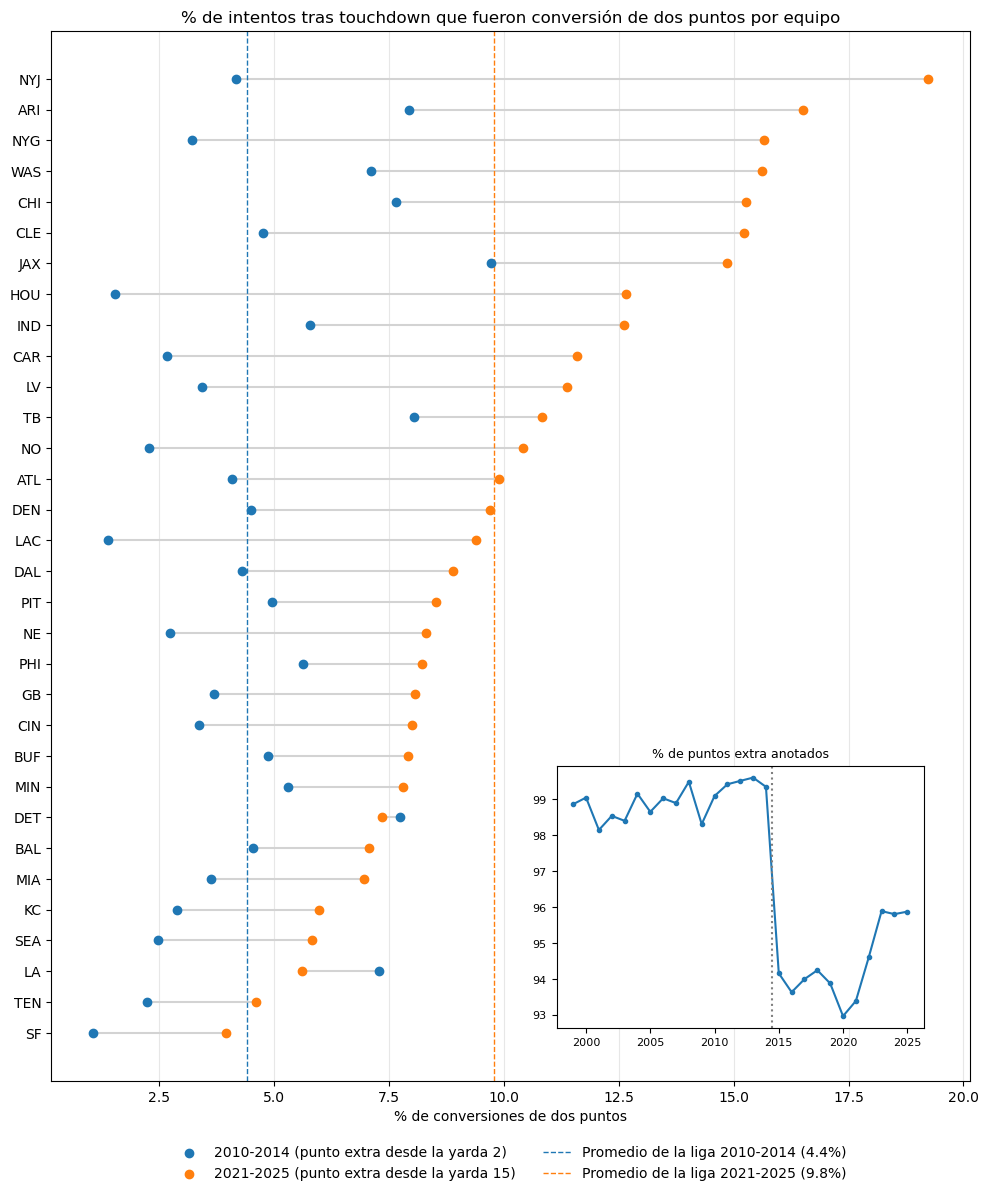

In [26]:
intentos = reg[reg["extra_point_result"].isin(["good", "failed", "blocked"])
               | (reg["two_point_attempt"] == 1)].copy()
intentos["dos_puntos"] = intentos["two_point_attempt"] == 1

antes = intentos[intentos["season"].between(2010, 2014)].groupby("posteam")["dos_puntos"].mean() * 100
despues = intentos[intentos["season"].between(2021, 2025)].groupby("posteam")["dos_puntos"].mean() * 100
equipos = pd.DataFrame({"antes": antes, "despues": despues}).dropna().sort_values("despues")

liga_antes = intentos[intentos["season"].between(2010, 2014)]["dos_puntos"].mean() * 100
liga_despues = intentos[intentos["season"].between(2021, 2025)]["dos_puntos"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 12))
ax.hlines(y=equipos.index, xmin=equipos["antes"], xmax=equipos["despues"], color="lightgray")
ax.scatter(equipos["antes"], equipos.index, label="2010-2014 (punto extra desde la yarda 2)", zorder=3)
ax.scatter(equipos["despues"], equipos.index, label="2021-2025 (punto extra desde la yarda 15)", zorder=3)
ax.axvline(liga_antes, color="tab:blue", linestyle="--", linewidth=1,
           label=f"Promedio de la liga 2010-2014 ({liga_antes:.1f}%)")
ax.axvline(liga_despues, color="tab:orange", linestyle="--", linewidth=1,
           label=f"Promedio de la liga 2021-2025 ({liga_despues:.1f}%)")
ax.set_title("% de intentos tras touchdown que fueron conversión de dos puntos por equipo")
ax.set_xlabel("% de conversiones de dos puntos")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False)
ax.grid(True, axis="x", alpha=0.3)

xp = reg[reg["extra_point_result"].isin(["good", "failed", "blocked"])]
pct_xp = xp.groupby("season")["extra_point_result"].apply(lambda x: (x == "good").mean() * 100)
mini = ax.inset_axes([0.55, 0.05, 0.4, 0.25])
mini.plot(pct_xp.index, pct_xp.values, marker="o", markersize=3)
mini.axvline(2014.5, color="gray", linestyle=":")
mini.set_title("% de puntos extra anotados", fontsize=9)
mini.tick_params(labelsize=8)
plt.tight_layout()
plt.show()

In [27]:
# Valores de apoyo del texto
print(f"Promedio de la liga: {liga_antes:.1f}% (2010-2014) → {liga_despues:.1f}% (2021-2025)")
print(f"Equipos que aumentaron su % de conversiones de dos: {(equipos['despues'] > equipos['antes']).sum()} de {len(equipos)}")

dos = reg[reg["two_point_attempt"] == 1]
por_temporada = pd.DataFrame({
    "% XP anotados": pct_xp,
    "intentos de 2": dos.groupby("season").size(),
    "% éxito de 2": dos.groupby("season")["two_point_conv_result"].apply(lambda x: (x == "success").mean() * 100),
})
print(por_temporada.loc[2010:].round(1))

desde_2015 = por_temporada.loc[2015:]
print(f"\nDesde 2015: punto extra = {desde_2015['% XP anotados'].mean() / 100:.3f} puntos esperados · "
      f"conversión de dos = {2 * desde_2015['% éxito de 2'].mean() / 100:.3f} puntos esperados")

Promedio de la liga: 4.4% (2010-2014) → 9.8% (2021-2025)
Equipos que aumentaron su % de conversiones de dos: 30 de 32
        % XP anotados  intentos de 2  % éxito de 2
season                                            
2010             99.1             50          52.0
2011             99.4             50          46.0
2012             99.5             56          51.8
2013             99.6             69          47.8
2014             99.3             58          48.3
2015             94.2             94          47.9
2016             93.6            105          48.6
2017             94.0             86          43.0
2018             94.3            130          50.8
2019             93.9            113          47.8
2020             93.0            131          48.1
2021             93.4            154          48.7
2022             94.6            119          47.1
2023             95.9            127          55.1
2024             95.8            135          40.7
2025           

### Qué muestra la gráfica

**1. El punto extra dejó de ser automático, de un año para otro.** El gráfico pequeño muestra un escalón muy claro: el porcentaje de puntos extra anotados pasó del **99.3% en 2014 al 94.2% en 2015**. Es decir, se pasó de fallar uno de cada 140 puntos extra a fallar uno de cada 17. Desde entonces se ha mantenido en torno al 94-96%, y en las últimas temporadas sube ligeramente (95.9% en 2025), seguramente por la misma mejora de los pateadores que se vio en el Capítulo 2.

**2. Las conversiones de dos se duplicaron.** El promedio de la liga pasó de alrededor del **4.4% de los intentos** en 2010-2014 a cerca del **10%** en 2021-2025. La gráfica por equipos muestra que no se trata de unos pocos equipos atrevidos, sino que el cambio es muy generalizado y que 30 de los 32 equipos intentan hoy más conversiones de dos que antes del cambio de regla.

**3. La regla creó un empate casi perfecto entre las dos opciones.** Este es quizás el resultado más interesante. Desde 2015:

- El punto extra se anota en torno al **94.4%** de las veces, así que vale de media unos **0.944 puntos**.
- La conversión de dos tiene éxito en torno al **47.6%** de las veces, así que vale de media unos **0.952 puntos** (dos puntos multiplicados por la probabilidad de conseguirlos)

**Las dos opciones valen prácticamente lo mismo.** Antes de 2015, el punto extra valía 0.99 puntos y era claramente la mejor opción en casi cualquier situación. Desde 2015, la decisión ya no tiene una respuesta automática, ya que depende del marcador, del momento del partido y de la confianza de cada equipo en su ataque desde la yarda 2.

### ¿Cumplió la regla su objetivo?

**En buena medida, sí.** El punto extra ya no es un trámite: se falla con cierta frecuencia y puede decidir partidos. Y las conversiones de dos, la jugada que la liga quería promover, son ahora el doble de frecuentes.

Pero hay un matiz, aunque hoy las dos opciones valen lo mismo en promedio, **los equipos siguen pateando el punto extra en 9 de cada 10 ocasiones**. Una explicación posible conecta con el Capítulo 1: ante dos opciones de valor similar, los entrenadores tienden a elegir la **más segura**, la que casi nunca falla, aunque la otra no sea peor en promedio. Creo que es la misma preferencia por evitar el fracaso visible que Romer detectó en el cuarto down.

## Conclusión del capítulo

- **Las reglas cambian el juego de forma inmediata y medible.** Tanto en la patada de salida como en el punto extra, cada cambio de regla produce un escalón claramente visible en los datos.
- **Los equipos responden a los incentivos:** cuando la liga hizo más valioso el touchback, hubo más touchbacks; cuando lo hizo menos valioso, volvieron los regresos.
- **Algunas consecuencias no se buscaban.** El cambio de 2011, pensado para la seguridad, hizo que los ataques empezaran 4 o 5 yardas más atrás.
- **El punto extra de 2015 consiguió lo que buscaba:** acabó con una jugada automática y creó una decisión real, con dos opciones de valor casi idéntico.

Con estos cambios, la liga movió también el punto de partida de los ataques. El siguiente capítulo analiza qué ha pasado con la **anotación**, si hoy los ataques son más eficientes, y en qué momentos del partido se anota.

---

# Capítulo 4. Cómo se anota

## El contexto

Los tres capítulos anteriores mostraron cambios en piezas concretas del juego: el cuarto down, los pateadores, la patada de salida y el punto extra. Este capítulo da un paso atrás y mira el resultado conjunto de todos esos cambios: **la anotación**.

Se responden dos preguntas:

1. **¿Son hoy más eficientes los ataques?** Es decir, de cada posesión, ¿cuántas acaban en puntos, y en qué fase del camino hacia la zona de anotación se nota la mejora?
2. **¿En qué momento del partido se anota?** Los puntos no se reparten de forma uniforme a lo largo de los 60 minutos, y su distribución revela mucho sobre cómo cambia el comportamiento de los equipos según el reloj.

Para ambas preguntas se comparan, como en el Capítulo 0, las cinco primeras temporadas del periodo (1999-2003) con las cinco últimas (2021-2025).

In [28]:
JUGADAS_ATAQUE = ["pass", "run", "punt", "field_goal", "qb_kneel", "qb_spike"]
jugadas_drive = reg[reg["fixed_drive"].notna() & reg["posteam"].notna() & reg["play_type"].isin(JUGADAS_ATAQUE)]

drives = jugadas_drive.groupby(["game_id", "posteam", "fixed_drive"]).agg(
    season=("season", "first"),
    yarda_inicio=("yardline_100", "first"),
    yarda_minima=("yardline_100", "min"),
    resultado=("fixed_drive_result", "first")).reset_index()

drives.loc[drives["resultado"] == "Touchdown", "yarda_minima"] = 0

print(f"Drives: {len(drives):,}")
print(drives["resultado"].value_counts())

Drives: 159,939
resultado
Punt                 62978
Touchdown            31811
Field goal           22042
Turnover             18440
End of half          10432
Turnover on downs     6640
Missed field goal     4550
Opp touchdown         2549
Safety                 415
Name: count, dtype: int64


## 1. ¿Son hoy más eficientes los ataques? El embudo de cada drive

Un **drive** es una posesión completa que empieza cuando un equipo recibe el balón y termina cuando anota, lo pierde o se acaba la mitad. Cada drive puede verse como un **embudo**, ya que todos empiezan, pero solo algunos consiguen avanzar hasta el medio campo; de esos, solo algunos llegan a la zona roja (las últimas 20 yardas), y de esos, solo algunos terminan en touchdown.

El gráfico muestra ese embudo para los dos periodos, uno junto al otro:

- **Cada barra** es una etapa del camino, y su longitud es el **porcentaje de drives que la alcanzan**.
- **El texto entre paréntesis** indica qué porcentaje de los drives de la etapa anterior consiguió pasar a esta. Por ejemplo, de los drives que llegan a la zona roja, qué porcentaje termina en touchdown.

Para que la definición de cada etapa sea coherente, un drive "cruza el medio campo" si en algún momento tuvo el balón en el campo rival, y "llega a la zona roja" si en algún momento estuvo a 20 yardas o menos de la zona de anotación. Los drives que terminan en touchdown cuentan siempre como que alcanzaron todas las etapas, aunque el touchdown llegara con un pase largo desde lejos.

In [29]:

etapas = ["Todos los drives", "Cruzan el medio campo", "Llegan a la zona roja", "Terminan en touchdown"]
periodos_embudo = {"1999-2003": (1999, 2003), "2021-2025": (2021, 2025)}

fig = go.Figure()
for nombre, (inicio, fin) in periodos_embudo.items():
    d = drives[drives["season"].between(inicio, fin)]
    valores = [100,
               (d["yarda_minima"] < 50).mean() * 100,
               (d["yarda_minima"] <= 20).mean() * 100,
               (d["resultado"] == "Touchdown").mean() * 100]
    fig.add_trace(go.Funnel(name=nombre, y=etapas, x=valores, textposition="inside",
                            textfont=dict(color="white", size=13),
                            texttemplate="<b>%{x:.1f}%</b><br>(%{percentPrevious:.0%})"))

fig.update_layout(title="El embudo de cada drive: % de drives que alcanzan cada etapa (entre parentesis el % respecto a la etapa anterior)",
                  width=1300, height=800, legend=dict(title="Periodo"),
                  uniformtext_minsize=12, uniformtext_mode="show")
fig.show()

In [30]:
# Valores de apoyo para el texto

cuartos_zona_roja = reg[(reg["down"] == 4) & (reg["yardline_100"] <= 20) & reg["play_type"].isin(["pass", "run"])]
exito_cuarto = ((cuartos_zona_roja["fourth_down_converted"] == 1)
                | ((cuartos_zona_roja["touchdown"] == 1) & (cuartos_zona_roja["td_team"] == cuartos_zona_roja["posteam"])))
claves_exito = set(map(tuple, cuartos_zona_roja.loc[exito_cuarto, ["game_id", "posteam", "fixed_drive"]].values))
drives["cuarto_down_rz"] = [(g, p, f) in claves_exito
                            for g, p, f in zip(drives["game_id"], drives["posteam"], drives["fixed_drive"])]

for nombre, (inicio, fin) in periodos_embudo.items():
    d = drives[drives["season"].between(inicio, fin)]
    zona_roja = d[d["yarda_minima"] <= 20]
    td = d[d["resultado"] == "Touchdown"]
    fg = d[d["resultado"] == "Field goal"]
    print(f"\n{nombre}:")
    print(f"  Drives: {len(d):,}")
    print(f"  Cruzan medio campo: {(d['yarda_minima'] < 50).mean() * 100:.1f}% | Zona roja: {len(zona_roja) / len(d) * 100:.1f}% | "
          f"Touchdown: {len(td) / len(d) * 100:.1f}% | Gol de campo: {len(fg) / len(d) * 100:.1f}%")
    print(f"  Drives que terminan en puntos (TD o FG): {(len(td) + len(fg)) / len(d) * 100:.1f}%")
    print(f"  Touchdowns por cada drive que llega a zona roja: {len(td) / len(zona_roja) * 100:.1f}%")
    print(f"  Inicio medio del drive (yardas desde la propia línea de gol): {(100 - d['yarda_inicio']).mean():.1f}")
    print(f"  % de touchdowns en drives con un 4º down convertido en zona roja: {td['cuarto_down_rz'].mean() * 100:.1f}%")
    print(f"  % de goles de campo en drives que NO llegaron a zona roja: {(fg['yarda_minima'] > 20).mean() * 100:.1f}%")


1999-2003:
  Drives: 29,994
  Cruzan medio campo: 55.5% | Zona roja: 31.0% | Touchdown: 17.6% | Gol de campo: 12.3%
  Drives que terminan en puntos (TD o FG): 29.9%
  Touchdowns por cada drive que llega a zona roja: 56.8%
  Inicio medio del drive (yardas desde la propia línea de gol): 31.7
  % de touchdowns en drives con un 4º down convertido en zona roja: 3.5%
  % de goles de campo en drives que NO llegaron a zona roja: 31.2%

2021-2025:
  Drives: 29,372
  Cruzan medio campo: 57.9% | Zona roja: 35.4% | Touchdown: 22.0% | Gol de campo: 15.5%
  Drives que terminan en puntos (TD o FG): 37.5%
  Touchdowns por cada drive que llega a zona roja: 62.2%
  Inicio medio del drive (yardas desde la propia línea de gol): 29.4
  % de touchdowns en drives con un 4º down convertido en zona roja: 7.1%
  % de goles de campo en drives que NO llegaron a zona roja: 41.0%


### Qué muestra el embudo

**Hoy los ataques llegan más lejos y convierten más.** Comparando los dos periodos:

| Etapa | 1999-2003 | 2021-2025 | Cambio |
|---|---|---|---|
| Cruzan el medio campo | 55.5% | 57.9% | +2.4 puntos |
| Llegan a la zona roja | 31.0% | 35.4% | +4.4 puntos |
| Terminan en touchdown | 17.6% | **22.0%** | **+4.4 puntos** |
| Terminan en gol de campo | 12.3% | 15.5% | +3.2 puntos |
| **Terminan en puntos (TD o gol de campo)** | **29.9%** | **37.5%** | **+7.6 puntos** |

La mejora se concentra en las **últimas etapas del embudo**. Cruzar el medio campo es solo un poco más frecuente que antes, pero llegar a la zona roja y, sobre todo, convertir una vez dentro ha mejorado mucho: de cada 100 drives que llegan a la zona roja, hoy terminan en touchdown 62, frente a 57 a principios de siglo.

El resultado de conjunto es importante, ya que **en un principio, 3 de cada 10 drives terminaban en puntos; hoy son casi 4 de cada 10**, y los touchdowns son un 25% más frecuentes que antes.

### Lo que no explica la mejora: el punto de partida

Una explicación sencilla sería que hoy los drives empiezan más cerca de la zona de anotación. Pero no es así: hoy los drives empiezan de media **más lejos** que antes (en la propia yarda 29.4, frente a la 31.7 en 1999-2003), en parte por los cambios en la patada de salida vistos en el Capítulo 3. La mejora de los ataques es todavía más meritoria, porque ocurre **empezando desde más atrás**.

### ¿Por qué son más eficientes los ataques?

Hay varias explicaciones posibles. Dos de ellas conectan con capítulos anteriores y **se pueden comprobar con los datos**:

**1. Ya no se renuncia al touchdown en cuarto down (Capítulo 1).** Si los equipos se la juegan más en cuarto down cerca de la zona de anotación, algunos drives que antes terminaban en gol de campo hoy terminan en touchdown. Los datos lo confirman: el porcentaje de touchdowns que vienen de drives en los que se **convirtió un cuarto down dentro de la zona roja** se duplicó, del 3.5% al 7.1%. Si se hace la cuenta, esto explica en torno a **una quinta parte** del aumento de touchdowns. Es una contribución real, aunque no la explicación principal.

**2. Pateadores con más alcance (Capítulo 2).** Con pateadores fiables desde más lejos, algunos drives que antes terminaban en despeje hoy terminan en un gol de campo largo. Los datos también lo confirman: el porcentaje de goles de campo que llegan en drives **que nunca alcanzaron la zona roja** pasó del 31.2% al 41.0%. Hoy, cuatro de cada diez goles de campo se patean desde fuera de la zona roja, lo que ayuda a explicar por qué los drives terminados en gol de campo también aumentaron.

Otras explicaciones son razonables pero **no se pueden comprobar con estos datos**, así que se presentan como hipótesis:

- **Reglas que protegen al quarterback y a los receptores.** A lo largo de estos años la liga ha endurecido los castigos a los golpes sobre el quarterback y el contacto con los receptores, lo que facilita el juego de pase.
- **Mejores esquemas y mejores decisiones de jugada (*playcalling*).** Los ataques modernos usan sistemas más variados y difíciles de defender, y cada vez más equipos apoyan sus decisiones en el análisis de datos.
- **Quarterbacks más completos**, capaces de lanzar y también de correr, lo que obliga a la defensa a cubrir más opciones.

Lo más probable es que la mejora sea la suma de todos estos factores, y no de uno solo.

## 2. ¿En qué momento del partido se anota? El reloj de los puntos

Si los puntos se repartieran de forma uniforme a lo largo del partido, cada minuto tendría más o menos la misma anotación. El siguiente gráfico comprueba si es así.

**Cómo leer el gráfico:** es un gráfico circular que representa el partido como la esfera de un reloj. El partido empieza arriba y avanza **en el sentido de las agujas del reloj**: cada cuarto ocupa un cuarto de vuelta (con un color distinto), y el descanso está abajo. El círculo está dividido en 120 bloques de 30 segundos. Para cada bloque:

- **La barra** muestra cuántos puntos se anotan en promedio, por partido, en esos 30 segundos, en las temporadas 2021-2025.
- **La línea negra** muestra lo mismo para 2000-2004, para comparar.

Los puntos se asignan al momento de la jugada en que se anotaron (touchdown, gol de campo, punto extra, conversión de dos o safety). Solo se considera el tiempo reglamentario, porque los puntos del tiempo extra no tienen un lugar en el reloj de 60 minutos.


In [31]:
anot = reg.copy()
anot["puntos"] = (6 * anot["touchdown"].fillna(0)
                  + 3 * (anot["field_goal_result"] == "made")
                  + 1 * (anot["extra_point_result"] == "good")
                  + 2 * (anot["two_point_conv_result"] == "success")
                  + 2 * anot["safety"].fillna(0)
                  + 2 * anot["defensive_two_point_conv"].fillna(0))

anot = anot[(anot["qtr"] <= 4) & anot["game_seconds_remaining"].notna()].copy()

segundos_cuarto = anot["game_seconds_remaining"] - (4 - anot["qtr"]) * 900
anot["transcurrido"] = (anot["qtr"] * 900 - segundos_cuarto).clip(upper=anot["qtr"] * 900 - 0.01)
anot = anot[anot["transcurrido"].between(0, 3599.99)]
anot["bloque"] = (anot["transcurrido"] // 30).astype(int)

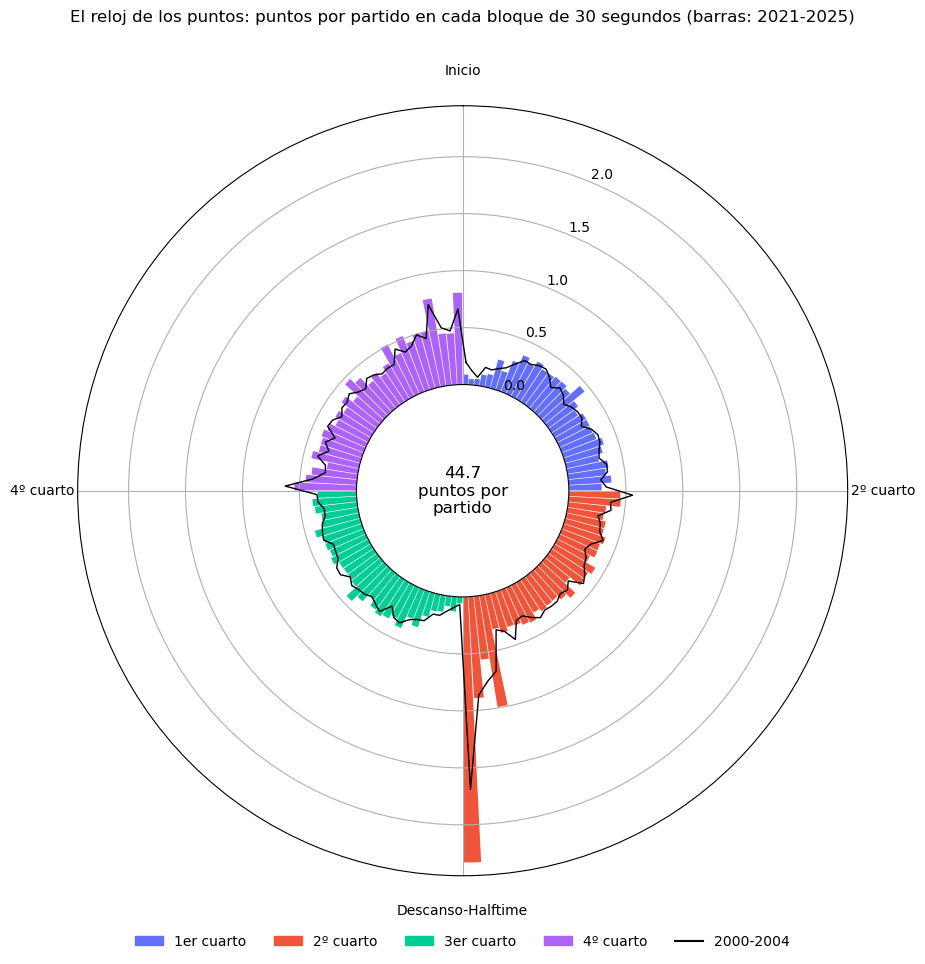

In [32]:
def puntos_por_bloque(inicio, fin):
    d = anot[anot["season"].between(inicio, fin)]
    partidos = reg[reg["season"].between(inicio, fin)]["game_id"].nunique()
    return d.groupby("bloque")["puntos"].sum().reindex(range(120), fill_value=0) / partidos

hoy = puntos_por_bloque(2021, 2025)
antes = puntos_por_bloque(2000, 2004)
angulos = (np.arange(120) + 0.5) * 2 * np.pi / 120

# Los mismos colores que usa plotly por defecto, uno por cuarto
colores_cuarto = ["#636EFA", "#EF553B", "#00CC96", "#AB63FA"]
colores_barras = [colores_cuarto[b // 30] for b in range(120)]

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_rorigin(-hoy.max() * 0.4)

ax.bar(angulos, hoy.values, width=2 * np.pi / 120 * 0.9, color=colores_barras)
ax.plot(np.append(angulos, angulos[0]), np.append(antes.values, antes.values[0]), color="black", linewidth=1)

ax.set_xticks(np.arange(4) * np.pi / 2)
ax.set_xticklabels(["Inicio", "2º cuarto", "Descanso-Halftime", "4º cuarto"])
ax.tick_params(axis="x", pad=15)
ax.text(0.5, 0.5, f"{hoy.sum():.1f}\npuntos por\npartido", transform=ax.transAxes,
        ha="center", va="center", fontsize=12)
ax.set_title("El reloj de los puntos: puntos por partido en cada bloque de 30 segundos (barras: 2021-2025)", pad=30)

leyenda = ([Patch(color=c, label=l) for c, l in zip(colores_cuarto, ["1er cuarto", "2º cuarto", "3er cuarto", "4º cuarto"])]
           + [Line2D([], [], color="black", label="2000-2004")])
ax.legend(handles=leyenda, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=5, frameon=False)
plt.show()

In [33]:
# Valores de apoyo para el texto
periodos_reloj = {"2000-2004": (2000, 2004), "2021-2025": (2021, 2025)}
for nombre, (inicio, fin) in periodos_reloj.items():
    serie = puntos_por_bloque(inicio, fin)
    print(f"\n{nombre} · bloques de 30 s con más puntos por partido:")
    for b, v in serie.nlargest(5).items():
        quedan = 900 - (b * 30) % 900
        print(f"  {b // 30 + 1}º cuarto, quedan {quedan // 60}:{quedan % 60:02d} → {v:.2f} puntos")

anot["segmento"] = np.select(
    [(anot["qtr"] == 2) & (anot["half_seconds_remaining"] <= 120),
     (anot["qtr"] == 4) & (anot["game_seconds_remaining"] <= 120),
     anot["qtr"] == 2],
    ["Últimos 2 min del 2º cuarto", "Últimos 2 min del 4º cuarto", "Resto del 2º cuarto"],
    default="Resto del partido")
minutos = pd.Series({"Últimos 2 min del 2º cuarto": 2, "Últimos 2 min del 4º cuarto": 2,
                     "Resto del 2º cuarto": 13, "Resto del partido": 43})

for nombre, (inicio, fin) in periodos_reloj.items():
    e = anot[anot["season"].between(inicio, fin)]
    partidos = e["game_id"].nunique()
    j = e[e["play_type"].isin(["pass", "run"]) & e["epa"].notna()]
    tabla_seg = pd.DataFrame({
        "puntos por minuto": e.groupby("segmento")["puntos"].sum() / minutos / partidos,
        "% de puntos de gol de campo": e[e["field_goal_result"] == "made"].groupby("segmento")["puntos"].sum()
                                        / e.groupby("segmento")["puntos"].sum() * 100,
        "jugadas por minuto": j.groupby("segmento").size() / minutos / partidos,
        "% de pases": j.groupby("segmento")["pass"].mean() * 100,
        "EPA por jugada": j.groupby("segmento")["epa"].mean(),
        "% de pérdidas de balón": (j["interception"].fillna(0) + j["fumble_lost"].fillna(0)).groupby(j["segmento"]).mean() * 100,
        "tiempos fuera por minuto": e.groupby("segmento")["timeout"].sum() / minutos / partidos,
    })
    print(f"\n{nombre}:")
    print(tabla_seg.round(3))


2000-2004 · bloques de 30 s con más puntos por partido:
  2º cuarto, quedan 0:30 → 1.69 puntos
  2º cuarto, quedan 1:00 → 0.87 puntos
  2º cuarto, quedan 1:30 → 0.75 puntos
  4º cuarto, quedan 2:00 → 0.73 puntos
  2º cuarto, quedan 2:00 → 0.68 puntos

2021-2025 · bloques de 30 s con más puntos por partido:
  2º cuarto, quedan 0:30 → 2.33 puntos
  2º cuarto, quedan 2:00 → 0.99 puntos
  2º cuarto, quedan 1:00 → 0.89 puntos
  4º cuarto, quedan 0:30 → 0.81 puntos
  4º cuarto, quedan 2:00 → 0.78 puntos

2000-2004:
                             puntos por minuto  % de puntos de gol de campo  \
Resto del 2º cuarto                      0.686                       20.610   
Resto del partido                        0.614                       18.887   
Últimos 2 min del 2º cuarto              1.995                       30.917   
Últimos 2 min del 4º cuarto              1.189                       19.500   

                             jugadas por minuto  % de pases  EPA por jugada  \
Resto del

### Qué muestra el reloj

**Los puntos no se reparten de forma uniforme y evidentemente hay un pico gigantesco justo antes del descanso.** El bloque de 30 segundos con más puntos de todo el partido es el **último medio minuto del segundo cuarto**. En 2021-2025 se anotan ahí **2.33 puntos por partido**, más del doble que en cualquier otro bloque del partido, y bastante más que en 2000-2004 (1.69 puntos). Los bloques siguientes en importancia también están en los últimos dos minutos de la primera mitad, empezando por el que sigue al aviso de los dos minutos.

El final del partido muestra un pico parecido, pero mucho más pequeño (el último medio minuto del cuarto cuarto suma unos 0.8 puntos por partido, alrededor de un tercio que el del descanso).

### ¿Por qué se anota tanto antes del descanso?

La explicación está en cómo cambia el comportamiento de los dos equipos cuando se acaba la primera mitad. Comparando los **últimos dos minutos del segundo cuarto** con el resto del partido:

| | Últimos 2 min del 2º cuarto | Resto del partido |
|---|---|---|
| Puntos por minuto | **2.39** (2.00 en 2000-2004) | 0.66 |
| Jugadas por minuto | 4.5 | 2.0 |
| % de pases | 80% | 58% |
| EPA por jugada | **+0.065** | −0.015 |
| % de pérdidas de balón | 2.5% | 1.8% |
| Tiempos fuera por minuto | 1.37 | 0.06 |
| % de los puntos que vienen de goles de campo | **35%** | 20% |

*(Temporadas 2021-2025, salvo que se indique otra cosa.)*

Estos números apoyan una explicación con varias piezas que encajan entre sí:

1. **Se juega mucho más rápido.** Con el aviso de los dos minutos y los tiempos fuera (se piden más de 20 veces más por minuto que en el resto del partido), el reloj se detiene constantemente. En dos minutos de reloj caben más del doble de jugadas que en dos minutos normales.

2. **Arriesgar sale barato.** Si un ataque pierde el balón con 30 segundos por jugar en la primera mitad, el rival apenas tiene tiempo de aprovecharlo, porque la mitad termina enseguida. Por eso los ataques pasan mucho más (el 80% de las jugadas) y asumen más riesgos, y si bien las pérdidas de balón son más frecuentes que en el resto del partido, perder el balón en ese momento cuesta poco por el limite del tiempo.

3. **Las defensas ceden terreno.** Ante un ataque con prisa, las defensas suelen protegerse contra el pase largo y conceden yardas cortas. Eso explica que el EPA por jugada sea **positivo** en este tramo, cuando en el resto del partido es negativo: es uno de los pocos momentos del juego en que el ataque tiene, en promedio, ventaja.

4. **Al final hay un gol de campo "gratis".** Muchos de esos drives rápidos no llegan a la zona de anotación, pero sí lo bastante cerca como para intentar un gol de campo en la última jugada. Por eso más de un tercio de los puntos de este tramo vienen de goles de campo, frente a un 20% en el resto del partido. Y como hoy los pateadores son fiables desde más lejos (Capítulo 2), ese gol de campo final es cada vez más accesible. Esto ayuda a explicar por qué el pico ha crecido: la proporción de goles de campo en este tramo subió del 31% en 2000-2004 al 35% hoy.

### ¿Y por qué el final del partido no es igual?

Los últimos dos minutos del cuarto cuarto también tienen más anotación que lo normal (1.25 puntos por minuto), pero mucho menos que antes del descanso, y su EPA por jugada es **negativo** (−0.06). La diferencia es que al final del partido **los dos equipos no tienen los mismos incentivos**, mientras el que va ganando quiere gastar el reloj, no anotar, y el que va perdiendo juega desesperado contra una defensa que ya sabe que va a pasar. Por eso es también el tramo con más pérdidas de balón (3.3%). Antes del descanso, en cambio, ninguno de los dos equipos tiene mucho que perder, y ambos tienen algo que ganar. Creo que esa combinación es la que produce el pico más alto del partido.

---

# Capítulo 5. Mitos y curiosidades

Los capítulos anteriores han descrito cómo cambió el juego. Este último capítulo tiene un enfoque distinto, en lugar de describir cambios, **pone a prueba algunas ideas muy extendidas** entre aficionados, comentaristas y entrenadores, para ver si los datos las respaldan.

Antes de los mitos, una curiosidad que conecta con todo lo anterior: **qué castigos se pitan hoy y cómo ha cambiado eso**. Después se analizan tres creencias populares:

1. **"Jugar en casa vale mucho."** ¿Cuánto gana realmente el equipo local, y qué pasó cuando los estadios se quedaron vacíos en 2020?
2. **"Pedir tiempo para congelar al pateador funciona."** ¿Fallan más los pateadores cuando el rival les hace esperar?
3. **"Ese quarterback es malo."** ¿O es que su línea ofensiva no lo protege?

## Curiosidad: el catálogo de castigos

En cada partido de la NFL se pitan alrededor de 12 castigos. Aunque el número total apenas ha cambiado en 25 años, **qué se castiga** sí ha cambiado bastante, como reflejo de los cambios en el juego y en las reglas.

### Una revisión previa de los datos

Antes de comparar castigos entre épocas hay que comprobar un detalle: a lo largo de los años, algunos castigos pueden aparecer registrados con nombres ligeramente distintos. Si una misma falta cambia de nombre, parecería que una "desaparece" y otra "aparece", cuando en realidad es la misma.

La siguiente celda lista todos los nombres de castigo que aparecen en los datos, con la primera y la última temporada en que se registran y el número total de veces. Solo se unifican los nombres que corresponden **exactamente a la misma falta**; faltas distintas, aunque sean parecidas, se mantienen separadas.

In [34]:
castigos = reg[(reg["penalty"] == 1) & reg["penalty_type"].notna()].copy()
castigos["castigo"] = castigos["penalty_type"].str.strip()

nombres = castigos.groupby("castigo").agg(primera=("season", "min"), ultima=("season", "max"),
                                          total=("play_id", "size")).sort_values("total", ascending=False)
print(nombres.to_string())

                                            primera  ultima  total
castigo                                                           
False Start                                    1999    2025  17237
Offensive Holding                              1999    2025  16493
Defensive Pass Interference                    1999    2025   6272
Defensive Offside                              1999    2025   4993
Defensive Holding                              1999    2025   4433
Unnecessary Roughness                          1999    2025   4371
Delay of Game                                  1999    2025   3641
Illegal Block Above the Waist                  1999    2025   2862
Roughing the Passer                            1999    2025   2587
Face Mask                                      1999    2025   2347
Neutral Zone Infraction                        1999    2025   2246
Offensive Pass Interference                    1999    2025   1982
Illegal Use of Hands                           1999    2025   

In [35]:
# Nombres distintos que corresponden exactamente a la misma falta
UNIFICAR = {
    "Defensive 12 On-field": "Defensive Too Many Men on Field",
    "Offensive 12 On-field": "Offensive Too Many Men on Field",
    "Horse Collar": "Horse Collar Tackle",
    "Player Out of Bounds on Punt": "Player Out of Bounds on Kick",
}
castigos["castigo"] = castigos["castigo"].replace(UNIFICAR)

TRADUCCION = {
    "Offensive Holding": "Holding ofensivo", "False Start": "Salida en falso",
    "Defensive Pass Interference": "Interferencia de pase defensiva", "Defensive Holding": "Holding defensivo",
    "Unnecessary Roughness": "Rudeza innecesaria", "Delay of Game": "Retraso de juego",
    "Defensive Offside": "Fuera de lugar defensivo", "Roughing the Passer": "Rudeza contra el pasador",
    "Neutral Zone Infraction": "Infracción de zona neutral", "Illegal Formation": "Formación ilegal",
    "Offensive Pass Interference": "Interferencia de pase ofensiva", "Illegal Contact": "Contacto ilegal",
    "Illegal Use of Hands": "Uso ilegal de las manos", "Ineligible Downfield Pass": "Jugador inelegible adelantado",
    "Illegal Block Above the Waist": "Bloqueo ilegal por encima de la cintura",
    "Intentional Grounding": "Pase intencionalmente al suelo", "Illegal Shift": "Desplazamiento ilegal (shift)",
    "Illegal Motion": "Movimiento ilegal (motion)", "Encroachment": "Encroachment",
    "Face Mask (15 Yards)": "Agarrar la máscara (15 yardas)", "Face Mask (5 Yards)": "Agarrar la máscara (5 yardas)",
    "Face Mask": "Agarrar la máscara", "Unsportsmanlike Conduct": "Conducta antideportiva",
    "Taunting": "Provocación", "Horse Collar Tackle": "Placaje por el cuello del jersey",
    "Defensive Too Many Men on Field": "Demasiados jugadores (defensa)",
    "Offensive Too Many Men on Field": "Demasiados jugadores (ataque)",
    "Too Many Men on Field": "Demasiados jugadores en el campo", "Roughing the Kicker": "Rudeza contra el pateador",
    "Chop Block": "Bloqueo bajo ilegal (chop block)", "Tripping": "Zancadilla", "Clipping": "Bloqueo por la espalda",
}
castigos["castigo_es"] = castigos["castigo"].map(TRADUCCION).fillna(castigos["castigo"])

partidos_por_temporada = reg.groupby("season")["game_id"].nunique()
por_partido = castigos.groupby(["season", "castigo_es"]).size().unstack(fill_value=0).div(partidos_por_temporada, axis=0)

inicio = por_partido.loc[1999:2003].mean()
hoy_c = por_partido.loc[2021:2025].mean()

TOP = 20
principales = hoy_c.sort_values(ascending=False).head(TOP).index
catalogo = pd.DataFrame({"Castigo": principales, "Hoy": hoy_c[principales].values, "Antes": inicio[principales].values})
otros = pd.DataFrame({"Castigo": ["Otros"], "Hoy": [hoy_c.drop(principales).sum()],
                      "Antes": [inicio.drop(principales, errors="ignore").sum()]})
catalogo = pd.concat([catalogo, otros], ignore_index=True)

catalogo["Cambio (%)"] = np.where(catalogo["Antes"] > 0.01, (catalogo["Hoy"] / catalogo["Antes"] - 1) * 100, np.nan)
catalogo["Texto cambio"] = np.where(catalogo["Cambio (%)"].isna(), "nuevo en los registros",
                                    catalogo["Cambio (%)"].map(lambda x: f"{x:+.0f}% vs 1999-2003"))
catalogo["Color"] = catalogo["Cambio (%)"].fillna(100).clip(-100, 100)

fig = px.treemap(catalogo, path=["Castigo"], values="Hoy", color="Color",
                 color_continuous_scale="RdBu_r", range_color=[-100, 100], color_continuous_midpoint=0,
                 custom_data=["Texto cambio"])
fig.update_traces(texttemplate="<b>%{label}</b><br>%{value:.2f} por partido<br>%{customdata[0]}")
fig.update_layout(title="El catálogo de castigos de hoy (2021-2025): tamaño = castigos por partido, color = cambio respecto a 1999-2003",
                  width=1200, height=700, coloraxis_colorbar=dict(title="Cambio (%)"))
fig.show()

In [36]:
# Valores de apoyo para el texto
print(f"Castigos por partido: {inicio.sum():.2f} (1999-2003) → {hoy_c.sum():.2f} (2021-2025)")
print(catalogo[["Castigo", "Antes", "Hoy", "Cambio (%)"]].round(2).to_string(index=False))

Castigos por partido: 12.58 (1999-2003) → 12.00 (2021-2025)
                                Castigo  Antes  Hoy  Cambio (%)
                       Holding ofensivo   2.45 2.33       -4.82
                        Salida en falso   2.74 2.28      -16.70
        Interferencia de pase defensiva   0.95 1.01        6.37
                      Holding defensivo   0.54 0.66       22.33
                     Rudeza innecesaria   0.48 0.61       26.84
                       Retraso de juego   0.50 0.60       21.39
               Fuera de lugar defensivo   0.94 0.54      -42.35
               Rudeza contra el pasador   0.34 0.38       14.31
             Infracción de zona neutral   0.11 0.33      216.45
                       Formación ilegal   0.10 0.30      187.58
                     Agarrar la máscara   0.34 0.30      -11.52
         Interferencia de pase ofensiva   0.26 0.26        1.23
                        Contacto ilegal   0.20 0.24       20.54
                Uso ilegal de las manos   0.

### Cómo leer el gráfico

El gráfico es un **mapa de árbol** (*treemap*): cada rectángulo es un tipo de castigo, y su **tamaño** es proporcional a cuántas veces se pita por partido en 2021-2025. El **color** indica cómo ha cambiado su frecuencia respecto a 1999-2003: en **rojo**, los castigos que hoy se pitan más; en **azul**, los que se pitan menos; en blanco, los que apenas han cambiado.

### Qué muestra el gráfico

**El número total de castigos apenas cambia:** se pasa de unos 12.6 castigos por partido en 1999-2003 a unos 12.0 en 2021-2025. Pero detrás de esa estabilidad hay movimientos importantes:

**1. Más castigos que protegen a los jugadores.** La **rudeza contra el pasador** se pita un 14% más que en un principio, y el **holding defensivo**, que penaliza a la defensa por sujetar a los receptores, un 22% más. Esto coincide con lo que se planteó como hipótesis en el Capítulo 4, que a lo largo de estos años, la liga ha endurecido la protección del quarterback y de los receptores. La **rudeza innecesaria** también aparece un 27% por encima, pero ese dato hay que tomarlo con cautela porque hasta 2014 existía una etiqueta genérica de "falta personal" en la que se registraban algunas faltas de este tipo, así que parte del aumento puede deberse a un cambio en la forma de registrarlas.

**2. Cambios en los errores del ataque antes del snap.** La **salida en falso**, que es un movimiento antes de tiempo de un jugador ofensivo, se pita un 17% menos. En cambio, el **retraso de juego**, que es no poner el balón en juego a tiempo, se pita un 21% más.

**3. Grandes cambios en las faltas de la defensa antes del snap.** La **infracción de zona neutral** se pita hoy tres veces más que a principios de siglo (+216%), mientras que el **fuera de lugar defensivo** (−42%) y el **encroachment** (−66%) se pitan mucho menos. Las tres son faltas distintas, con definiciones distintas en el reglamento, y los datos no permiten saber por qué ha cambiado tanto su frecuencia relativa.

**4. Faltas que crecen con los ataques modernos.** El **jugador inelegible adelantado** (un liniero que avanza más de lo permitido en una jugada de pase) se multiplica por más de tres (+255%), y la **formación ilegal** casi se triplica (+188%). Este aumento coincide con la popularización de las jugadas en las que el quarterback decide en el último momento si pasa o entrega el balón para una carrera (las llamadas *RPO*), en las que los linieros bloquean como si fuera una carrera. Los datos no permiten comprobar esa relación, pero el momento en que se produce encaja con ella.

*Nota sobre los datos: algunos castigos cambiaron de nombre en los registros a lo largo de los años (por ejemplo, "Defensive 12 On-field" pasó a llamarse "Defensive Too Many Men on Field" en 2018). En esos casos, en los que se trata exactamente de la misma falta, los dos nombres se han unificado. Las faltas distintas, aunque sean parecidas, se mantienen separadas.*

## Mito 1: "Jugar en casa vale mucho"

### La creencia

Es una de las ideas más arraigadas del deporte: el equipo local tiene ventaja. En el fútbol americano se suelen dar varias explicaciones:

- **El ruido del público**, que dificulta la comunicación del ataque visitante.
- **La presión sobre los árbitros**, que podrían favorecer inconscientemente al local.
- **El viaje y el descanso**: el visitante cambia de ciudad, a veces de huso horario, y duerme fuera de casa.
- **La familiaridad con el estadio**: el césped, el viento, la luz.

### El experimento natural de 2020

En la temporada 2020, por la pandemia de COVID-19, la mayoría de los partidos de la NFL se jugaron **sin público o con un aforo muy reducido**. Eso convirtió a 2020 en un **experimento natural**, si una parte importante de la ventaja de local viene del público, en 2020 esa ventaja debería haberse reducido mucho.

### Qué se mide

La gráfica muestra, para cada temporada, el **porcentaje de partidos que ganó el equipo local** (los empates cuentan como media victoria). Se excluyen los partidos en sede neutral, en los que no hay un verdadero local. La línea gris horizontal marca el 50%, es decir, lo que se esperaría si jugar en casa no diera ninguna ventaja. Las líneas discontinuas marcan el promedio de dos periodos: 1999-2018 y 2019-2025.

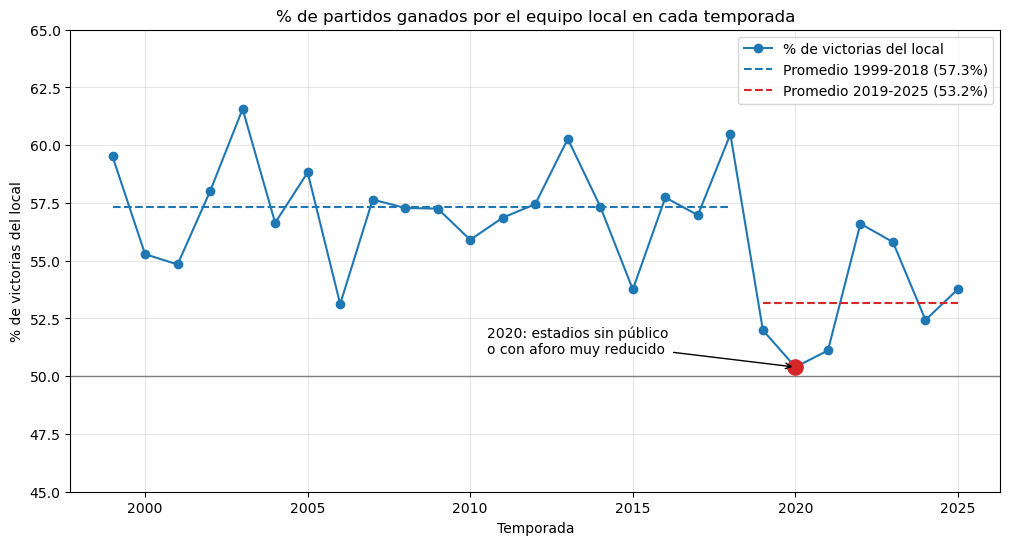

Promedio 1999-2018: 57.3% · Promedio 2019-2025: 53.2%
{1999: 59.5, 2000: 55.3, 2001: 54.8, 2002: 58.0, 2003: 61.6, 2004: 56.6, 2005: 58.8, 2006: 53.1, 2007: 57.6, 2008: 57.3, 2009: 57.3, 2010: 55.9, 2011: 56.9, 2012: 57.5, 2013: 60.3, 2014: 57.3, 2015: 53.8, 2016: 57.7, 2017: 57.0, 2018: 60.5, 2019: 52.0, 2020: 50.4, 2021: 51.1, 2022: 56.6, 2023: 55.8, 2024: 52.4, 2025: 53.8}


In [37]:
partidos_reg = reg.groupby("game_id").agg(season=("season", "first"), local=("home_score", "first"),
                                          visitante=("away_score", "first"), sede=("location", "first"))
partidos_reg = partidos_reg[partidos_reg["sede"] != "Neutral"]
partidos_reg["victoria_local"] = (partidos_reg["local"] > partidos_reg["visitante"]) + 0.5 * (partidos_reg["local"] == partidos_reg["visitante"])

victorias_local = partidos_reg.groupby("season")["victoria_local"].mean() * 100
promedio_1 = partidos_reg[partidos_reg["season"] <= 2018]["victoria_local"].mean() * 100
promedio_2 = partidos_reg[partidos_reg["season"] >= 2019]["victoria_local"].mean() * 100

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(victorias_local.index, victorias_local.values, marker="o", label="% de victorias del local")
ax.axhline(50, color="gray", linewidth=1)
ax.hlines(promedio_1, 1999, 2018, color="tab:blue", linestyle="--", label=f"Promedio 1999-2018 ({promedio_1:.1f}%)")
ax.hlines(promedio_2, 2019, 2025, color="tab:red", linestyle="--", label=f"Promedio 2019-2025 ({promedio_2:.1f}%)")
ax.scatter([2020], [victorias_local.loc[2020]], color="tab:red", s=120, zorder=3)
ax.annotate("2020: estadios sin público\no con aforo muy reducido", (2020, victorias_local.loc[2020]),
            xytext=(2010.5, 51), arrowprops=dict(arrowstyle="->"))
ax.set_title("% de partidos ganados por el equipo local en cada temporada")
ax.set_xlabel("Temporada")
ax.set_ylabel("% de victorias del local")
ax.set_ylim(45, 65)
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.show()

print(f"Promedio 1999-2018: {promedio_1:.1f}% · Promedio 2019-2025: {promedio_2:.1f}%")
print(victorias_local.round(1).to_dict())

### Qué muestra la gráfica

**La ventaja de local existe, pero se ha reducido.** Entre 1999 y 2018, el equipo local ganó en promedio alrededor del **57%** de los partidos, de forma bastante estable: la gran mayoría de los años por encima del 55%. Desde 2019, el promedio ha bajado a alrededor del **53%**.

**2020 fue el año con menos ventaja de local de toda la serie:** el local ganó solo el 50.4% de los partidos, prácticamente lo mismo que lanzar una moneda al aire. Es justo lo que se esperaría si el público fuera una parte importante de la ventaja de jugar en casa.

### Pero hay un detalle que impide sacar una conclusión rotunda

**En 2019, con los estadios llenos, la ventaja de local ya había caído** hasta el 52.0%, casi tan bajo como en 2020. Es decir, el año anterior a la pandemia ya mostraba una ventaja muy pequeña, sin que el público hubiera desaparecido. Además, con unos 250 partidos por temporada, el porcentaje de un solo año puede variar varios puntos por puro azar.

Por eso, la lectura honesta de la gráfica es esta:

- **Lo que los datos sí muestran:** la ventaja de local se ha reducido en los últimos años, y 2020, sin público, fue el mínimo.

Esto sugiere que la ventaja de local depende de **más factores que el público**, y que alguno de ellos ha cambiado en los últimos años. Algunas hipótesis razonables, que estos datos no permiten comprobar, son la mejora en las condiciones de viaje y descanso de los equipos, o la preparación específica para jugar en estadios ruidosos.

**Conclusión del mito:** jugar en casa sí da ventaja, pero **menos de lo que se suele creer** (hoy, un equipo local gana algo más de la mitad de sus partidos, no muchos más), y esa ventaja se ha ido reduciendo.

*Nota: los dos periodos de la gráfica (1999-2018 y 2019-2025) se eligieron después de observar los datos, para resumir visualmente el cambio. Son una descripción, no una prueba estadística de que exista un punto de ruptura exacto en 2019.*

## Mito 2: "Pedir tiempo para congelar al pateador funciona"

### La creencia

El equipo que va a patear un gol de campo decisivo se prepara, el pateador se concentra, y justo antes del snap, el entrenador rival pide tiempo fuera. La idea es **"congelar" al pateador**: hacerle esperar y pensar en la presión, con la esperanza de que falle. Muchos entrenadores lo hacen de forma casi automática en los finales apretados.

### Qué se mide

Se comparan los goles de campo **en situación de presión**, definida como:

- en los **últimos 3 minutos del cuarto cuarto o en el tiempo extra**,
- con el equipo que patea **empatado o perdiendo por 3 puntos o menos**, es decir, una patada que empata o pone por delante.

Dentro de esas patadas, se considera que el pateador fue **congelado** si la jugada inmediatamente anterior fue un **tiempo fuera pedido por la defensa**. Se incluyen temporada regular y playoffs, para tener el mayor número posible de patadas.

Como la probabilidad de acertar depende mucho de la distancia, la comparación se hace **por tramos de distancia**, así, en cada par de barras se comparan patadas de longitud parecida. Bajo cada tramo se indica el número de patadas.

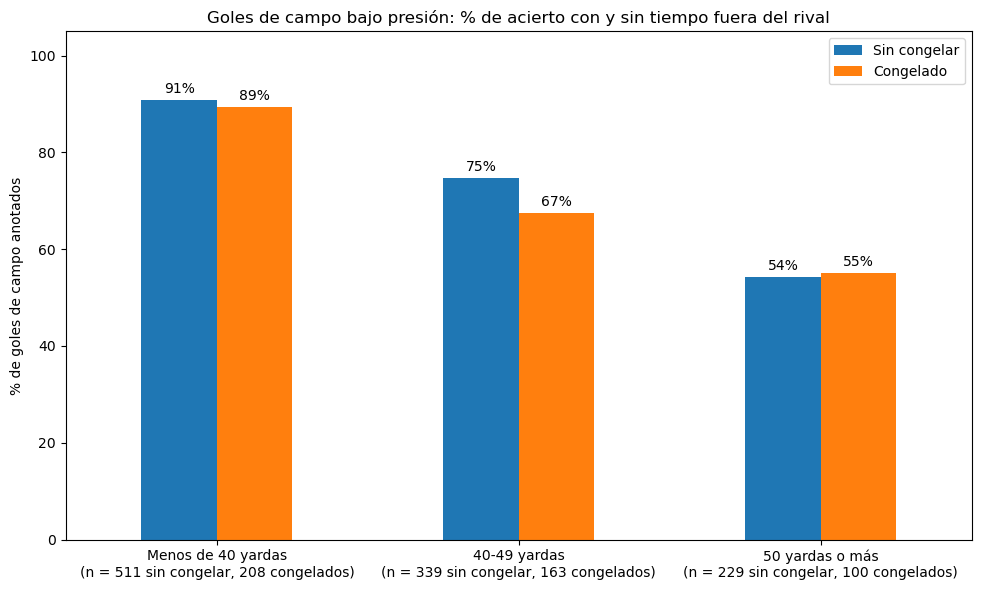

In [38]:
anterior = pbp.groupby("game_id")[["timeout", "timeout_team"]].shift(1)
fg_todos = pbp[(pbp["play_type"] == "field_goal") & pbp["field_goal_result"].notna() & pbp["kick_distance"].notna()].copy()
fg_todos["anotado"] = (fg_todos["field_goal_result"] == "made").astype(int)
fg_todos["congelado"] = ((anterior.loc[fg_todos.index, "timeout"] == 1)
                         & (anterior.loc[fg_todos.index, "timeout_team"] == fg_todos["defteam"]))

presion = ((((fg_todos["qtr"] == 4) & (fg_todos["game_seconds_remaining"] <= 180)) | (fg_todos["qtr"] >= 5))
           & fg_todos["score_differential"].between(-3, 0))
bajo_presion = fg_todos[presion & fg_todos["kick_distance"].between(18, 65)].copy()
bajo_presion["distancia"] = pd.cut(bajo_presion["kick_distance"], bins=[0, 39, 49, 70],
                                   labels=["Menos de 40 yardas", "40-49 yardas", "50 yardas o más"])
bajo_presion["grupo"] = np.where(bajo_presion["congelado"], "Congelado", "Sin congelar")

resumen_hielo = bajo_presion.groupby(["distancia", "grupo"], observed=True)["anotado"].agg(["mean", "size"]).unstack()
acierto = resumen_hielo["mean"][["Sin congelar", "Congelado"]] * 100
n = resumen_hielo["size"][["Sin congelar", "Congelado"]]

ax = acierto.plot(kind="bar", figsize=(10, 6), rot=0)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f%%", padding=3)
ax.set_xticklabels([f"{d}\n(n = {n.loc[d, 'Sin congelar']} sin congelar, {n.loc[d, 'Congelado']} congelados)" for d in acierto.index])
ax.set_title("Goles de campo bajo presión: % de acierto con y sin tiempo fuera del rival")
ax.set_xlabel("")
ax.set_ylabel("% de goles de campo anotados")
ax.set_ylim(0, 105)
ax.legend(title="")
plt.tight_layout()
plt.show()

In [39]:
# Valores de apoyo para el texto
total = bajo_presion.groupby("grupo")["anotado"].agg(["mean", "size"])
dist_media = bajo_presion.groupby("grupo")["kick_distance"].mean()
print(f"Patadas bajo presión: {len(bajo_presion):,}")
print(pd.DataFrame({"% acierto": total["mean"] * 100, "patadas": total["size"], "distancia media": dist_media}).round(1))
print("\nPor tramo de distancia:")
print(acierto.round(1))
print(n)

Patadas bajo presión: 1,550
              % acierto  patadas  distancia media
grupo                                            
Congelado          74.5      471             40.7
Sin congelar       77.9     1079             40.0

Por tramo de distancia:
grupo               Sin congelar  Congelado
distancia                                  
Menos de 40 yardas          90.8       89.4
40-49 yardas                74.6       67.5
50 yardas o más             54.1       55.0
grupo               Sin congelar  Congelado
distancia                                  
Menos de 40 yardas           511        208
40-49 yardas                 339        163
50 yardas o más              229        100


### Qué muestra la gráfica

De las 1,550 patadas bajo presión, **471 (un 30%) fueron "congeladas"** por un tiempo fuera del rival, lo que confirma que es una táctica muy habitual.

**En conjunto, los pateadores congelados aciertan algo menos:** un **74.5%**, frente al **77.9%** de los que no fueron congelados. Y no es porque intentaran patadas más largas, ya que la distancia media de ambos grupos es prácticamente la misma (unas 40 yardas).

**Al separar por distancia, se ve dónde está el efecto:**

| Distancia | Sin congelar | Congelado | Diferencia |
|---|---|---|---|
| Menos de 40 yardas | 90.8% | 89.4% | −1.4 puntos |
| 40-49 yardas | 74.6% | **67.5%** | **−7.1 puntos** |
| 50 yardas o más | 54.1% | 55.0% | +0.9 puntos |

La diferencia se concentra en las **distancias medias, de 40 a 49 yardas**, donde los pateadores congelados aciertan unos 7 puntos porcentuales menos. Y tiene sentido, en las patadas cortas, el pateador casi nunca falla, con o sin espera; y en las muy largas, lo que manda es la dificultad de la propia patada. Es en la zona intermedia, donde la patada es exigente pero asequible, donde un momento de duda puede marcar la diferencia.

**Conclusión del mito:** los datos apuntan a que **congelar al pateador sí sirve, pero solo un poco y sobre todo en patadas de distancia media**. Hay que tomar el resultado con cautela, porque el número de patadas congeladas en cada tramo es pequeño (entre 100 y 200), y con tan pocas patadas una diferencia de algunos puntos puede deberse en parte al azar. Aun así, como pedir el tiempo fuera no cuesta casi nada, la práctica tiene sentido.

## Mito 3: "Ese quarterback es malo"

### La creencia

Cuando un ataque no funciona, el primer señalado suele ser el **quarterback**. Pero en el fútbol americano, el quarterback depende mucho de los cinco jugadores que tiene delante, la **línea ofensiva**, cuya misión es protegerlo para que tenga tiempo de lanzar. Un quarterback que recibe golpes constantemente lanzará peor, sea bueno o malo. La pregunta es: **¿cuánto peor rinde un quarterback cuando lo presionan?**

### Qué se mide, y por qué de esta forma

Los datos públicos no incluyen una medida completa de la presión (por ejemplo, cuántas veces el quarterback tuvo que lanzar con prisa). Pero sí registran dos cosas: los **sacks** (cuando la defensa derriba al quarterback antes de lanzar) y los **golpes al quarterback** (cuando lo golpean mientras lanza o justo después). Se usa como medida de presión el **porcentaje de jugadas de pase en las que el quarterback sufrió un sack o un golpe**.

Para que la comparación sea justa hay que resolver dos problemas:

1. **Comparar a cada quarterback consigo mismo.** Si se comparan quarterbacks distintos, se mezcla la presión con la calidad de cada uno. Por eso, para cada quarterback y temporada, se compara su rendimiento en los **partidos en que recibió más presión de la habitual** con los partidos en que recibió **menos presión de la habitual**. Así, la calidad del quarterback queda fuera de la comparación.
2. **No contar los sacks en el rendimiento.** Un sack ya es, por definición, una jugada con EPA negativo. Si se incluyeran, la relación entre presión y mal rendimiento saldría "fabricada". Por eso el rendimiento se mide con el **EPA de las jugadas de pase que no terminaron en sack**; es decir, cómo lanza el quarterback cuando sí consigue lanzar.

Se analizan todos los partidos en que un quarterback tuvo al menos 15 jugadas de pase. Esos partidos se dividen en cinco grupos iguales, desde los días en que el quarterback recibió mucha menos presión de la habitual hasta los días en que recibió mucha más. Para cada grupo, la barra muestra **cuánto mejor o peor que su propio promedio** rindió el quarterback.

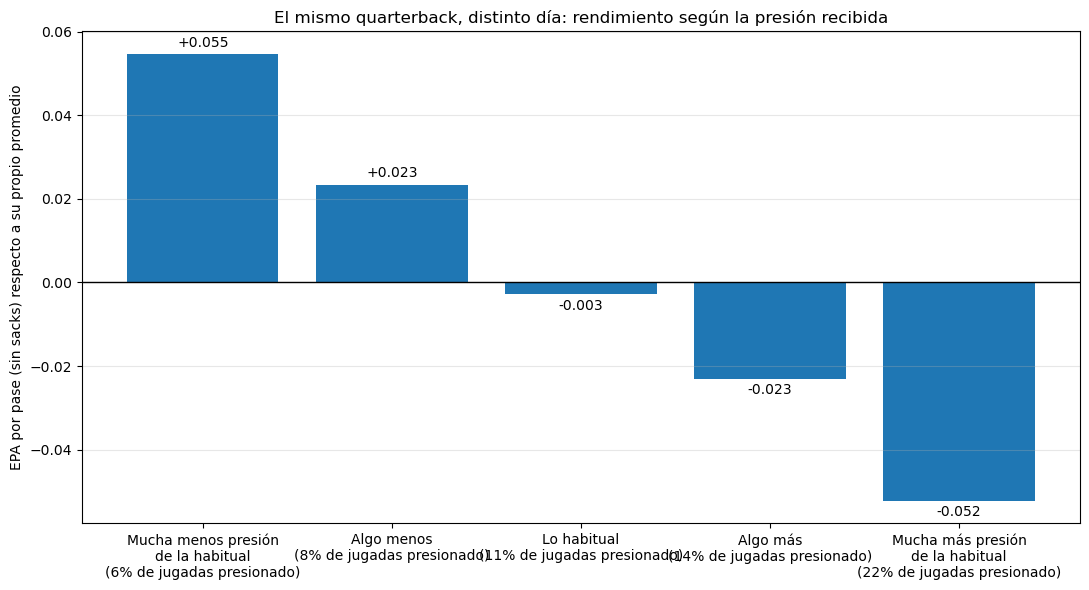

In [40]:
pases = reg[(reg["qb_dropback"] == 1) & reg["passer_player_id"].notna() & reg["epa"].notna()
            & reg["play_type"].isin(["pass", "run"])].copy()
pases["presionado"] = ((pases["sack"].fillna(0) + pases["qb_hit"].fillna(0)) > 0).astype(int)

claves = ["season", "game_id", "passer_player_id"]
qb_partido = pases.groupby(claves).agg(jugadas=("epa", "size"), presion=("presionado", "mean"))
epa_sin_sacks = pases[pases["sack"].fillna(0) == 0].groupby(claves)["epa"].mean().rename("epa_sin_sacks")
qb_partido = qb_partido.join(epa_sin_sacks).dropna()
qb_partido = qb_partido[qb_partido["jugadas"] >= 15].reset_index()

grupo_qb = qb_partido.groupby(["season", "passer_player_id"])
qb_partido["presion_vs_su_media"] = qb_partido["presion"] - grupo_qb["presion"].transform("mean")
qb_partido["epa_vs_su_media"] = qb_partido["epa_sin_sacks"] - grupo_qb["epa_sin_sacks"].transform("mean")

etiquetas_q = ["Mucha menos presión\nde la habitual", "Algo menos", "Lo habitual", "Algo más", "Mucha más presión\nde la habitual"]
qb_partido["quintil"] = pd.qcut(qb_partido["presion_vs_su_media"], 5, labels=etiquetas_q)
resumen_qb = qb_partido.groupby("quintil", observed=True).agg(presion=("presion", "mean"),
                                                              epa=("epa_vs_su_media", "mean"),
                                                              partidos=("epa_vs_su_media", "size"))

fig, ax = plt.subplots(figsize=(11, 6))
barras = ax.bar([f"{q}\n({p:.0%} de jugadas presionado)" for q, p in zip(resumen_qb.index, resumen_qb["presion"])],
                resumen_qb["epa"])
ax.bar_label(barras, fmt="%+.3f", padding=3)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("El mismo quarterback, distinto día: rendimiento según la presión recibida")
ax.set_ylabel("EPA por pase (sin sacks) respecto a su propio promedio")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
# Valores de apoyo
print(f"Partidos de quarterback analizados: {len(qb_partido):,}")
print(f"% de jugadas de pase con sack o golpe al quarterback: {pases['presionado'].mean() * 100:.1f}%")
print(f"Correlación presión - rendimiento (mismo quarterback): "
      f"{np.corrcoef(qb_partido['presion_vs_su_media'], qb_partido['epa_vs_su_media'])[0, 1]:+.3f}")
print(resumen_qb.round(3))

Partidos de quarterback analizados: 14,144
% de jugadas de pase con sack o golpe al quarterback: 12.4%
Correlación presión - rendimiento (mismo quarterback): -0.139
                                     presion    epa  partidos
quintil                                                      
Mucha menos presión\nde la habitual    0.061  0.055      2831
Algo menos                             0.083  0.023      2827
Lo habitual                            0.112 -0.003      2828
Algo más                               0.143 -0.023      2829
Mucha más presión\nde la habitual      0.220 -0.052      2829


### Qué muestra la gráfica

**El mismo quarterback rinde de forma muy distinta según la presión que recibe.** De los algo más de 14,000 partidos de quarterback analizados, en promedio un 12% de las jugadas de pase terminan en sack o golpe. Pero ese porcentaje varía mucho de un partido a otro, y con él, el rendimiento:

- En los días con **mucha menos presión de la habitual** (alrededor del 6% de jugadas con sack o golpe), el quarterback rinde **+0.055 EPA por pase por encima de su propio promedio**.
- En los días con **mucha más presión de la habitual** (alrededor del 22%), rinde **−0.052 EPA por pase por debajo** de su promedio.

La relación es **perfectamente escalonada**: a cada grupo con más presión, peor rendimiento. Y hay que recordar que esto es **sin contar los sacks**: incluso cuando consigue lanzar, el quarterback presionado lanza peor.

Para poner la diferencia en perspectiva: unos 0.11 puntos esperados por pase, en un partido con unos 35 pases, equivalen a casi **4 puntos esperados por partido**. Es la diferencia entre el mismo quarterback en un buen día de su línea ofensiva y en un mal día.

### Una advertencia necesaria

Estos datos no permiten afirmar que la culpa sea siempre de la línea ofensiva, por dos motivos:

- **Parte de la presión la provoca el propio quarterback.** Un quarterback que tarda en decidir y retiene el balón recibe más golpes, así que en un "mal día" del quarterback también puede haber más presión.
- **Las buenas defensas hacen las dos cosas a la vez:** presionan más y además cubren mejor a los receptores, lo que empeora el rendimiento por ambas vías.

**Conclusión del mito:** no se puede juzgar a un quarterback sin mirar cuánta presión recibe. **El mismo jugador parece otro cuando lo presionan**, así que una parte de lo que se atribuye al "mal quarterback" corresponde en realidad a las circunstancias que lo rodean, empezando por su línea ofensiva.

## Conclusión del capítulo

- **Los castigos cuentan la evolución del juego:** el número total es estable, pero hoy se pitan más faltas de protección a los jugadores y más faltas propias de los ataques modernos.
- **Jugar en casa da ventaja, pero menos de lo que se cree:** el local gana algo más de la mitad de sus partidos, y esa ventaja se ha reducido en los últimos años. 2020, sin público, fue el mínimo, pero el descenso había empezado antes.
- **Congelar al pateador parece funcionar un poco, sobre todo en patadas de distancia media:** de 40 a 49 yardas, los pateadores congelados aciertan unos 7 puntos porcentuales menos; en distancias cortas y muy largas, la diferencia es prácticamente nula.
- **La presión transforma a los quarterbacks:** el mismo jugador rinde mucho peor en los días en que su línea ofensiva no lo protege.

---

# Conclusiones

Este trabajo ha recorrido 27 temporadas de la NFL (1999-2025) y más de 1.2 millones de jugadas para responder una pregunta: **¿cómo y por qué ha cambiado el juego?** 

La respuesta tiene dos protagonistas: los entrenadores, que aprendieron a tomar decisiones basadas en datos, y la propia liga, que cambió las reglas.

## 1. Los datos tardaron en cambiar las decisiones, pero acabaron cambiándolas

El caso más claro es el **cuarto down**. Con los datos de 1999-2005 se comprueba que, en cuarto y corto, **jugársela era mejor que patear en casi todas las zonas del campo**: en medio campo, por ejemplo, jugársela en 4th & 1 aportaba de media casi un punto esperado (+0.98), mientras que despejar lo restaba (−0.37). Es lo mismo que había señalado el economista David Romer a principios de siglo.

Sin embargo, la liga tardó más de una década en reaccionar. El porcentaje de cuartos downs jugados se mantuvo en torno al **7%** entre 1999 y 2017, y solo a partir de 2018 se disparó, hasta el **17.4% en 2025**. En 4th & 1, los equipos pasaron de jugársela una de cada tres veces a hacerlo tres de cada cuatro. Y el cambio fue inteligente, no temerario: se concentró en las distancias cortas y en las zonas donde los datos lo recomendaban.

## 2. Los jugadores también cambiaron

El alcance de los pateadores ha crecido **unas 8 o 9 yardas** en 25 años. La distancia a la que aciertan la mitad de sus intentos pasó de 51.6 a 60.2 yardas. Los datos permiten descartar las explicaciones externas: la mejora aparece **bajo techo y al aire libre, con frío y con calor**, y a pesar de que hoy se intentan **el triple de patadas largas**. La explicación más probable es la más directa, que los pateadores son mejores.

## 3. Cada cambio de regla cambió el juego

- **La patada de salida** se reformó varias veces por seguridad. Los regresos pasaron del 85% de las patadas (1999-2010) a un mínimo del **21.7% en 2023**, hasta que la liga cambió de rumbo y, con el *dynamic kickoff* y el touchback en la yarda 35, volvieron al **76.2% en 2025**. Por el camino hubo efectos no buscados, por ejemplo, el cambio de 2011 hizo que los ataques empezaran unas 4 yardas más atrás, y posteriormente se tuvo que volver a ajustar.
- **El punto extra** se alejó en 2015 porque se anotaba más del 99% de las veces. La regla funcionó: el acierto bajó al ~94%, las conversiones de dos se duplicaron (del 4.4% al 9.8% de los intentos, con aumentos en 30 de los 32 equipos) y **las dos opciones quedaron prácticamente empatadas en valor** (0.944 frente a 0.952 puntos esperados).

En todos los casos, es claro que **los equipos responden a los incentivos**, y cuando la liga ha hecho más valiosa una opción, los equipos la eligen más.

## 4. El resultado: ataques más eficientes

Hoy, **casi 4 de cada 10 drives terminan en puntos**, frente a 3 de cada 10 al principio, y eso a pesar de que los drives empiezan de media más lejos de la zona de anotación. Parte de la mejora conecta con los capítulos anteriores (cuartos downs jugados en la zona roja y goles de campo desde más lejos), y el resto probablemente se deba a reglas que favorecen el pase y a ataques más sofisticados.

La anotación, además, no se reparte por igual, ya que el **último medio minuto antes del descanso** es el momento con más puntos de todo el partido (2.33 puntos por partido en 2021-2025, frente a 1.69 en 2000-2004), creo yo porque es el único momento en que ninguno de los dos equipos tiene mucho que perder.

## 5. Algunas creencias tienen soporte en los datos y otras no

- **Jugar en casa da ventaja, pero menos de lo que se cree:** el local gana algo más de la mitad de sus partidos (57.3% en 1999-2018 y 53.2% desde 2019), y 2020, sin público, fue el mínimo (50.4%).
- **Congelar al pateador parece servir, aunque parece ser que solo un poco**, sobre todo en patadas de distancia media.
- **La presión transforma a los quarterbacks:** el mismo jugador rinde mucho peor en los días en que su línea ofensiva no lo protege.

## Reflexión final

El fútbol americano de 2025 es, en sus reglas básicas, el mismo de 1999: cuatro downs, diez yardas, seis puntos por touchdown. Pero se juega de otra manera. Los entrenadores arriesgan donde los datos lo justifican, los pateadores llegan más lejos, las reglas han redibujado jugadas enteras y los ataques convierten más posesiones en puntos. Visualizar 27 años de jugadas permite ver algo que, partido a partido, es casi invisible. **El juego cambia despacio, pero cambia, y casi siempre en la dirección que marcan los incentivos y la evidencia.**

# Limitaciones

**1. Los datos son observacionales.** Este trabajo describe relaciones, pero no puede demostrar causas. Cuando se proponen explicaciones que los datos no permiten comprobar (por ejemplo, por qué el cambio en el cuarto down llegó en 2018, o la relación entre algunos castigos y las jugadas tipo *RPO*), se presentan explícitamente como hipótesis.

**2. Efectos de selección.** Varias comparaciones están afectadas por el hecho de que los equipos eligen cuándo hacer cada cosa:

- En la época de Romer, los equipos solo se la jugaban en cuarto down cuando creían tener buenas posibilidades, lo que puede inflar el éxito de esa opción.
- Los entrenadores deciden cuándo congelar al pateador.
- Parte de la presión que recibe un quarterback la provoca él mismo.

En cada caso se ha intentado reducir el sesgo con la comparación adecuada, pero no se puede eliminar del todo.

**3. Dependencia de un modelo.** El EPA y la probabilidad de victoria los calcula nflfastR con modelos estadísticos. Son la referencia estándar en la analítica del fútbol americano, pero pueden equivocarse en situaciones poco frecuentes.

**4. Calidad de los datos.** Durante el análisis se detectaron y trataron varios problemas:

- En la temporada **1999**, el registro del reloj no es fiable (demasiadas jugadas aparecen en el primer segundo de un cuarto), por lo que se excluyó del análisis del reloj de los puntos.
- En un partido de 2011 (Detroit en Nueva Orleans), los datos de origen contienen jugadas duplicadas. No afecta a ninguno de los periodos analizados.
- Algunos castigos **cambiaron de nombre** en los registros; solo se unificaron los que corresponden exactamente a la misma falta. Además, hasta 2014 existía una etiqueta genérica de "falta personal", lo que dificulta comparar algunas faltas de rudeza entre épocas.
- Las **patadas cortas intencionales** se identifican buscando la palabra "onside" en la descripción de la jugada, lo que podría no detectar algún caso.
- En 2023, las recepciones con *fair catch* convertidas en touchback aparecen registradas mayoritariamente como touchback, por lo que no se pueden separar del todo ambos resultados.
- La **presión** sobre el quarterback se mide solo con sacks y golpes registrados; los datos públicos no incluyen otras formas de presión.

**5. Muestras pequeñas en algunos análisis.** El número de patadas congeladas en cada tramo de distancia o el porcentaje de victorias locales de una sola temporada se basan en pocos cientos de casos, por lo que pequeñas diferencias pueden deberse en parte al azar.

**6. Periodos de comparación.** La mayoría de las comparaciones se hacen entre los primeros y los últimos años del periodo. En algunos casos (como los dos promedios de la ventaja de local) los cortes se eligieron después de observar los datos, con un fin descriptivo, y no deben interpretarse como puntos de ruptura demostrados.

**7. Alcance.** El análisis se centra en la temporada regular de la NFL. No se han usado datos de seguimiento de jugadores (posición de cada jugador en el campo), que permitirían análisis más finos de la presión, las coberturas o las formaciones.

# Referencias

## Datos y herramientas

- **nflverse.** Datos de *play-by-play* de la NFL, temporadas 1999-2025. Repositorio público: https://github.com/nflverse/nflverse-data/releases/tag/pbp
- **Carl, S. y Baldwin, B.** *nflfastR: Functions to Efficiently Access NFL Play by Play Data.* https://www.nflfastr.com
- **Baldwin, B. (2020).** *nflfastR EP, WP, and CP models.* Open Source Football. https://www.opensourcefootball.com/posts/2020-09-28-nflfastr-ep-wp-and-cp-models/

## Estudios

- **Romer, D. (2006).** Do Firms Maximize? Evidence from Professional Football. *Journal of Political Economy*, 114(2). https://eml.berkeley.edu/~dromer/papers/JPE_April06.pdf

## Cambios de reglas

- **Football Zebras.** *Chronology of kickoff rules changes.* https://www.footballzebras.com/2018/05/chronology-of-kickoff-rules-changes/
- **Arrowhead Pride (2018).** *Dave Toub weighs in on changes to kickoff rules.* https://www.arrowheadpride.com/2018/8/3/17648592/dave-toub-weighs-in-on-changes-to-kickoff-rules
- **ESPN Stats & Info (2016).** *Will new kickoff rule lead to more touchbacks?* https://www.espn.com/blog/statsinfo/post/_/id/115502/will-new-kickoff-rule-lead-to-more-touchbacks
- **ESPN (2015).** *NFL changes PAT rule for 2015.* https://africa.espn.com/nfl/story/_/id/12915634/nfl-change-extra-point-kicks-longer-distance

## Librerías de Python

pandas, NumPy, Matplotlib, seaborn, Plotly, PyArrow, SciPy y pywaffle.

# Entorno y reproducibilidad

Este notebook se desarrolló y ejecutó con **Python 3.13.9** y las siguientes versiones de librerías (incluidas en el fichero `requirements.txt` de la entrega):

| Librería | Versión |
|---|---|
| pandas | 2.3.3 |
| numpy | 2.4.6 |
| matplotlib | 3.10.6 |
| seaborn | 0.13.2 |
| plotly | 6.3.0 |
| pyarrow | 21.0.0 |
| scipy | 1.16.3 |
| pywaffle | 1.2.0 |

**Contenido de la entrega:**

- Este notebook (`.ipynb`), ejecutado completo de principio a fin con el kernel limpio.
- `data/nfl_pbp_1999_2025.parquet`: el fichero reducido con todos los datos que usa el análisis.
- `requirements.txt`: las librerías y versiones necesarias.

Si el fichero reducido no está presente, la celda de preparación de datos lo reconstruye automáticamente descargando los ficheros originales desde nflverse (unos 500 MB).